# Klasterisasi Puskesmas Berdasarkan Indikator Stunting Menggunakan K-Means sebagai Pendukung Penentuan Wilayah Prioritas Penanganan di Dinas Kesehatan Kota Padang

Rumusan Masalah: Puskesmas mana yang sebaiknya diprioritaskan Dinkes untuk penanganan stunting, dan seperti apa profil masalahnya?



| # | Tahap | Isinya dalam satu kalimat |
|---|---|---|
| 1 | Problem Definition | Apa masalahnya, untuk siapa, dan apa batasannya |
| 2 | Data Collection | Memuat 3 file BNBA dan data rujukan Dinkes |
| 3 | EDA | Memeriksa data sebelum diolah |
| 4 | Data Preprocessing | Membersihkan data yang salah ketik atau tidak masuk akal |
| 5 | Feature Engineering & Selection | Mengubah data per anak menjadi 5 angka per puskesmas |
| 6 | Data Splitting | Menguji apakah pola Maret-April masih berlaku di Mei |
| 7 | Model Selection | Membandingkan 3 jenis algoritma pengelompokan |
| 8 | Model Training | Melatih model dan memberi nama kelompok |
| 9 | Hyperparameter Tuning | Mencari jumlah kelompok (K) yang cocok |
| 10 | Model Evaluation | Menguji hasil dari banyak sisi dan menilai seberapa bisa dipercaya |
| 11 | Finalisasi Model | Menyimpan model dan catatan batasannya |
| 12 | Deployment & Monitoring | Memakai model untuk data bulan baru dan memantau perubahan |


**Pembagian kerja:**
- Dhyva = Tahap 1-5
- Aqila = Tahap 6-9 dan validasi Tahap 10
- Madani = Visualisasi Tahap 10 dan Tahap 11-12.

In [ ]:
# =====PERSIAPAN=====
import os, glob, json, datetime, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
try:
    from IPython.display import display      # tersedia di Google Colab / Jupyter
except ImportError:
    display = print

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 40)

# ======PENGATURAN=====
SEED = 42                      # angka awal pengacak: seed sama = hasil sama
K = 3                          # jumlah kelompok (3 tingkat prioritas)
N_INIT = 200                   # berapa kali K-Means dicoba dari titik awal berbeda
BULAN = ['2026-03', '2026-04', '2026-05']
BULAN_LATIH = ['2026-03', '2026-04']   # data latih untuk uji Tahap 6
BULAN_UJI = '2026-05'                  # data uji untuk Tahap 6
BUANG_USIA_DI_ATAS_60_BULAN = True     # BNBA untuk balita 0-59 bulan; False = pertahankan baris usia > 60 bulan
fitur_klaster = ['Prevalensi_(%)', 'Sangat_pendek_(%)', 'Stunting_wasting_(%)', 'BB_tidak_naik_(%)', 'Bumil_KEK_(%)']

print("Persiapan selesai.")


Persiapan selesai.


## Tahap 1 - Problem Definition (Merumuskan Masalah)


**Masalah:** Penanganan stunting (makanan bergizi, pemantauan, dll.) pada dasarnya sama untuk setiap anak. Yang bisa diputuskan berbeda adalah wilayah mana yang diprioritaskan.

**Unit analisis:** 24 puskesmas Kota Padang dari 11 kecamatan

**Jenis tugas:** Unsupervised learning (klasterisasi)


**Pengguna:** Dinas Kesehatan Kota Padang dan kepala puskesmas.

**Batasan model:**
- Data hanya 3 bulan. Hasilnya potret, bukan tren. Tren butuh data minimal 1 tahun.
- BNBA hanya berisi balita yang sudah tercatat stunting, jadi prevalensi dianggap sebagai kasus tercatat per sasaran balita.
- Semua dari 3 file BNBA asli dan rekap Dinas Kesehatan

## Tahap 2 - Data Collection (Mengumpulkan Data)


**Sumber data**
1. BNBA Balita Stunting Maret, April, Mei 2026 (data per anak).
2. Rekap Dinkes per puskesmas: **sasaran balita** dan **% ibu hamil KEK**

In [ ]:
# ======MEMUAT FILE BNBA======
def ada_file_bnba():
    return all(any('bnba' in f.lower() and kata in f.lower() for f in glob.glob('*.xlsx'))
               for kata in ('maret', 'april', 'mei'))

if not ada_file_bnba():                       # di Colab: minta unggah file bila belum ada
    try:
        from google.colab import files
        print("File BNBA belum ada. Pilih 3 file BNBA (Maret, April, Mei):")
        files.upload()
    except ImportError:
        pass

def cari_file(kata):
    hasil = [f for f in glob.glob('*.xlsx') if 'bnba' in f.lower() and kata in f.lower()]
    if len(hasil) != 1:
        raise FileNotFoundError(f"Harus ada tepat 1 file BNBA '{kata}' di folder kerja, ditemukan: {hasil}")
    return hasil[0]

file_bulan = {'2026-03': cari_file('maret'), '2026-04': cari_file('april'), '2026-05': cari_file('mei')}

# Pembersihan memakai ISI DATA (bukan nomor baris):
#   a) buang blok yang kolomnya bergeser (Kab/Kota bukan 'KOTA PADANG')
#   b) buang baris yang tanggal ukurnya bukan bulan file tersebut (salinan bulan lain / salah ketik tahun)
def muat_bulan(path, bulan, verbose=True):
    xls = pd.ExcelFile(path)
    sheet = 'Application List' if 'Application List' in xls.sheet_names else xls.sheet_names[0]
    df = pd.read_excel(xls, sheet_name=sheet)
    df = df.drop(columns=['Nama Ortu', 'No'], errors='ignore')      # samakan susunan kolom
    mentah = len(df)
    df['Tanggal Pengukuran'] = pd.to_datetime(df['Tanggal Pengukuran'], errors='coerce')
    df = df[df['Kab/Kota'].astype(str).str.strip().str.upper() == 'KOTA PADANG']
    n_geser = mentah - len(df)
    df = df[df['Tanggal Pengukuran'].dt.strftime('%Y-%m') == bulan]
    n_bulan_lain = mentah - n_geser - len(df)
    df = df.copy()
    df['Bulan'] = bulan
    if verbose:
        print(f"[{bulan}] baris mentah {mentah} | blok bergeser dibuang {n_geser} | beda bulan dibuang {n_bulan_lain} | dipakai {len(df)}")
    return df

df_gabungan = pd.concat([muat_bulan(p, b) for b, p in file_bulan.items()], ignore_index=True)
print(f"\nTotal gabungan 3 bulan (belum dibersihkan nilainya): {len(df_gabungan)} baris, {df_gabungan.shape[1]} kolom")
display(df_gabungan.groupby('Bulan').size().rename('Jumlah_baris').to_frame())
display(df_gabungan.head(3))


[2026-03] baris mentah 1472 | blok bergeser dibuang 0 | beda bulan dibuang 1 | dipakai 1471
[2026-04] baris mentah 1487 | blok bergeser dibuang 0 | beda bulan dibuang 0 | dipakai 1487
[2026-05] baris mentah 4604 | blok bergeser dibuang 1472 | beda bulan dibuang 1487 | dipakai 1645

Total gabungan 3 bulan (belum dibersihkan nilainya): 4603 baris, 23 kolom


,Jumlah_baris
Bulan,
2026-03,1471
2026-04,1487
2026-05,1645


,NIK,Nama,JK,Tgl Lahir,Prov,Kab/Kota,Kec,Pukesmas,Desa/Kel,Posyandu,Tanggal Pengukuran,Berat,Tinggi,BB/U,ZS BB/U,TB/U,ZS TB/U,BB/TB,ZS BB/TB,Naik Berat Badan,PMT Aktif,Tindakan,Bulan
0,3758223194,MUHAMMAD KENZO,L,2023-11-25,SUMATERA BARAT,KOTA PADANG,NANGGALO,NANGGALO,KURAO PAGANG,melati,2026-03-09,9.0,78.0,Sangat Kurang,-3.06,Sangat Pendek,-3.67,Gizi Baik,-1.55,T,-,NaN,2026-03
1,910249840,RAFAZA,L,2024-08-21,SUMATERA BARAT,KOTA PADANG,KURANJI,KURANJI,KALUMBUK,KP.MARAPAK,2026-03-09,9.5,76.5,Normal,-1.36,Pendek,-2.31,Gizi Baik,-0.38,T,-,NaN,2026-03
2,1271062207220000,AZLAN JUHENDRA,L,2022-07-22,SUMATERA BARAT,KOTA PADANG,LUBUK BEGALUNG,LUBUK BEGALUNG,KAMPUNG BARU NAN XX,FLAMBOYAN V,2026-03-05,10.6,88.5,Sangat Kurang,-3.13,Sangat Pendek,-3.04,Gizi Kurang,-2.14,N,-,NaN,2026-03


## Tahap 3 - EDA (Memeriksa Data)

Tahap Exploratory Data Analysis (EDA) dilakukan untuk memeriksa kualitas data mentah sebelum masuk ke tahap pengolahan lanjutan. Pada tahap ini, kita mengecek jumlah baris, sebaran data, serta mengidentifikasi adanya nilai-nilai ekstrem atau anomali yang perlu dibersihkan pada Tahap 4.

In [ ]:
# Salinan khusus EDA (data asli df_gabungan tidak diubah)
eda = df_gabungan.copy()
for col in ['Berat', 'Tinggi', 'ZS BB/U', 'ZS TB/U', 'ZS BB/TB']:
    eda[col] = pd.to_numeric(eda[col], errors='coerce')
eda['Tgl Lahir'] = pd.to_datetime(eda['Tgl Lahir'], errors='coerce')
eda['Usia_Bulan'] = ((eda['Tanggal Pengukuran'] - eda['Tgl Lahir']).dt.days / 30.4375).round(2)
for col_w in ['Kec', 'Pukesmas', 'Desa/Kel']:
    eda[col_w] = eda[col_w].astype(str).str.strip().str.upper()

print(f"Baris: {len(eda)} | Puskesmas: {eda['Pukesmas'].nunique()} | Kecamatan: {eda['Kec'].nunique()} | Kelurahan: {eda['Desa/Kel'].nunique()}")
miss = eda.isna().mean().mul(100).round(1)
print("\nKolom dengan nilai kosong (%):")
display(miss[miss > 0].sort_values(ascending=False).to_frame('Kosong (%)'))
print("Ringkasan statistik kolom numerik:")
display(eda[['Usia_Bulan', 'Berat', 'Tinggi', 'ZS BB/U', 'ZS TB/U', 'ZS BB/TB']].describe().round(2))


Baris: 4603 | Puskesmas: 24 | Kecamatan: 11 | Kelurahan: 103

Kolom dengan nilai kosong (%):


,Kosong (%)
Tindakan,32.0
Posyandu,0.2


Ringkasan statistik kolom numerik:


,Usia_Bulan,Berat,Tinggi,ZS BB/U,ZS TB/U,ZS BB/TB
count,4603.00,4603.00,4603.00,4603.00,4603.00,4603.00
mean,31.50,11.59,80.70,0.60,-2.71,8.12
std,16.91,55.24,13.22,96.27,0.67,142.31
min,0.00,1.20,39.00,-5.81,-5.96,-6.14
25%,19.04,8.20,74.00,-2.75,-2.97,-1.68
50%,32.95,10.40,83.60,-2.17,-2.52,-0.92
75%,45.48,12.00,90.50,-1.57,-2.22,0.05
max,60.98,2400.00,101.00,4259.47,-2.01,7777.15


,Jumlah baris
|Z-score| > 10,37
Berat > 35 kg,6
Berat > 100 (kemungkinan satuan gram),4
Usia <= 0 bulan atau kosong,91
Usia > 60 bulan,33


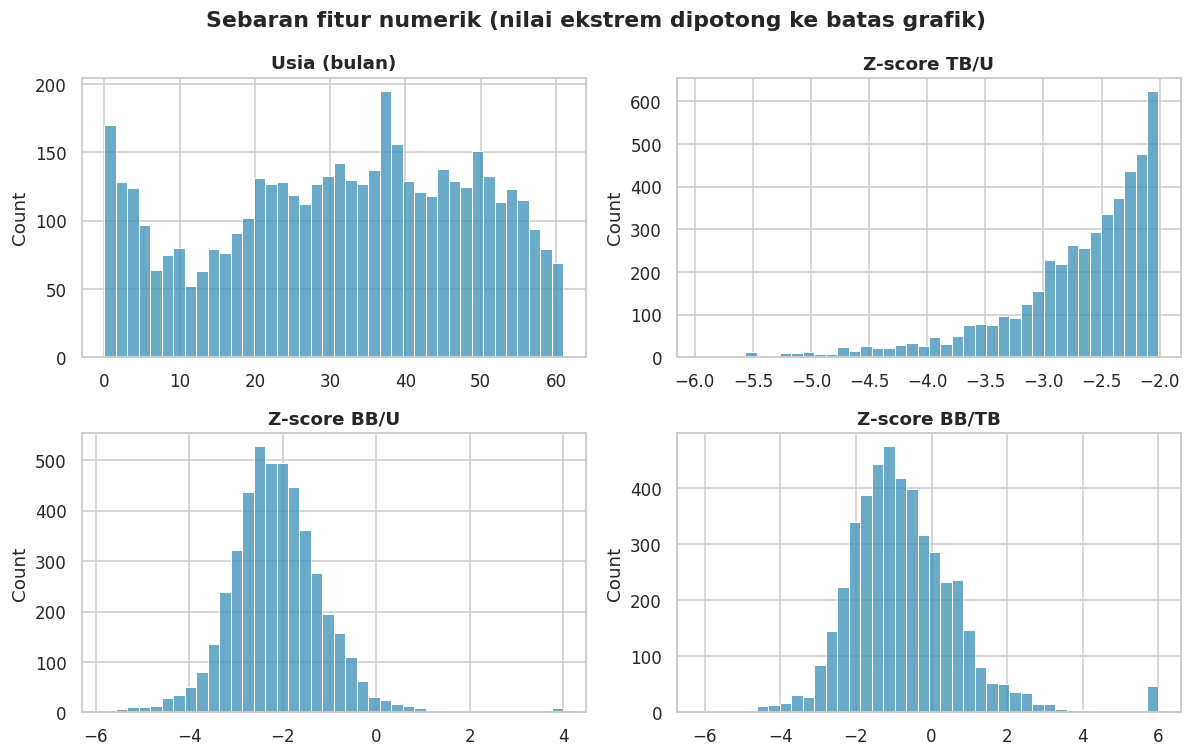

In [ ]:
# Indikasi nilai tidak wajar (yang akan ditangani di Tahap 4)
anomali = pd.Series({
    '|Z-score| > 10': int((eda[['ZS BB/U', 'ZS TB/U', 'ZS BB/TB']].abs() > 10).any(axis=1).sum()),
    'Berat > 35 kg': int((eda['Berat'] > 35).sum()),
    'Berat > 100 (kemungkinan satuan gram)': int((eda['Berat'] > 100).sum()),
    'Usia <= 0 bulan atau kosong': int(((eda['Usia_Bulan'] <= 0) | eda['Usia_Bulan'].isna()).sum()),
    'Usia > 60 bulan': int((eda['Usia_Bulan'] > 60).sum()),
}).to_frame('Jumlah baris')
display(anomali)

fig, ax = plt.subplots(2, 2, figsize=(11, 7), dpi=110)
for a, (col, rng, ttl) in zip(ax.ravel(), [
        ('Usia_Bulan', (0, 70), 'Usia (bulan)'), ('ZS TB/U', (-8, 4), 'Z-score TB/U'),
        ('ZS BB/U', (-8, 4), 'Z-score BB/U'), ('ZS BB/TB', (-8, 6), 'Z-score BB/TB')]):
    sns.histplot(eda[col].dropna().clip(*rng), bins=40, color='#3a8fb7', ax=a)
    a.set_title(ttl, fontweight='bold'); a.set_xlabel('')
fig.suptitle('Sebaran fitur numerik (nilai ekstrem dipotong ke batas grafik)', fontweight='bold')
plt.tight_layout(); plt.show()


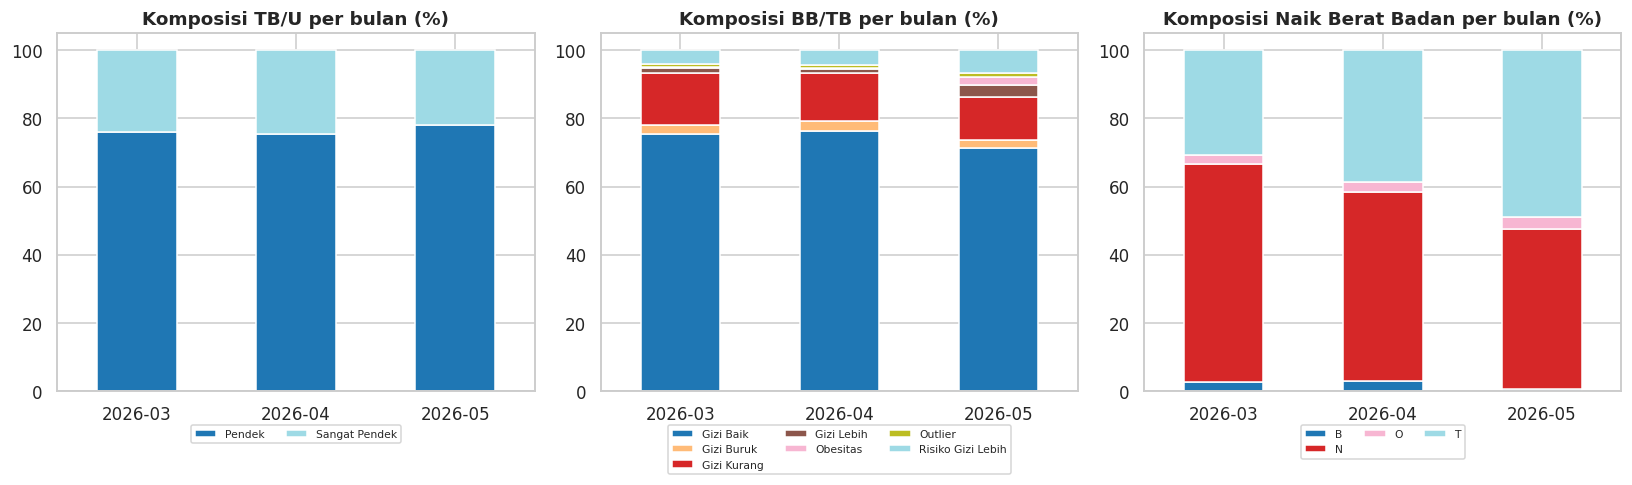

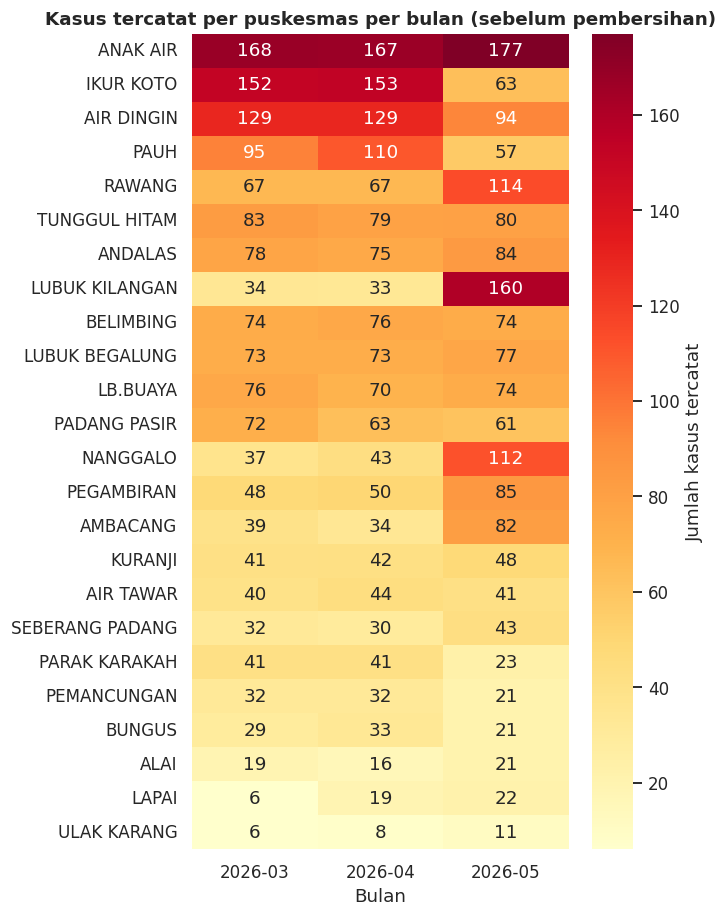

Total baris per bulan: {'2026-03': 1471, '2026-04': 1487, '2026-05': 1645}


In [ ]:
# Komposisi status gizi per bulan + volume pelaporan per bulan
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), dpi=110)
for a, col in zip(ax, ['TB/U', 'BB/TB', 'Naik Berat Badan']):
    tab = pd.crosstab(eda['Bulan'], eda[col].astype(str).str.strip(), normalize='index') * 100
    tab.plot(kind='bar', stacked=True, ax=a, colormap='tab20', edgecolor='white')
    a.set_title(f'Komposisi {col} per bulan (%)', fontweight='bold'); a.set_xlabel(''); a.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3)
    a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

pivot = eda.pivot_table(index='Pukesmas', columns='Bulan', values='Nama', aggfunc='count').fillna(0).astype(int)
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index]
plt.figure(figsize=(6.5, 8.5), dpi=110)
sns.heatmap(pivot, annot=True, fmt='d', cmap='YlOrRd', cbar_kws={'label': 'Jumlah kasus tercatat'})
plt.title('Kasus tercatat per puskesmas per bulan (sebelum pembersihan)', fontweight='bold'); plt.ylabel('')
plt.tight_layout(); plt.show()
print("Total baris per bulan:", pivot.sum().to_dict())


In [ ]:
# TEMUAN EDA
print("TEMUAN EDA (dasar keputusan di Tahap 4-6)\n")
print("1. Baris tidak wajar yang akan dibersihkan di Tahap 4:")
for k, v in anomali['Jumlah baris'].items(): print(f"   - {k}: {v} baris")
vol = pivot.sum()
print("\n2. Jumlah kasus tercatat tiap bulan: " + ", ".join(f"{b}: {int(v)}" for b, v in vol.items()))
if len(vol) > 1:
    arah = "lebih banyak" if vol.iloc[-1] > vol.iloc[:-1].mean() else "lebih sedikit"
    print(f"   Bulan terakhir {arah} dari rata-rata bulan sebelumnya ({vol.iloc[-1]:.0f} dibanding {vol.iloc[:-1].mean():.0f}).")
bbt = pd.crosstab(eda['Bulan'], eda['Naik Berat Badan'].astype(str).str.strip(), normalize='index') * 100
if 'T' in bbt.columns:
    print("   Persentase anak yang berat badannya tidak naik ('T') per bulan: " + ", ".join(f"{b}: {v:.1f}%" for b, v in bbt['T'].items()))
rasio = (pivot.max(axis=1) / pivot.replace(0, np.nan).min(axis=1)).sort_values(ascending=False).head(3)
print("\n3. Puskesmas yang jumlah kasusnya paling berubah antarbulan (terbesar dibanding terkecil):")
for p, r in rasio.items(): print(f"   - {p}: {' -> '.join(str(int(x)) for x in pivot.loc[p])}  (x{r:.1f})")
print("   Lonjakan sebesar ini bisa karena laporan yang makin lengkap, bukan karena kasus benar-benar naik (perlu konfirmasi Dinkes).")
print("   Karena itu pengelompokan memakai rata-rata 3 bulan, dan kestabilan antarbulan diuji di Tahap 6 dan 10.")
semua_stunting = (pd.to_numeric(eda['ZS TB/U'], errors='coerce') < -2).mean() * 100
print(f"\n4. Balita dengan Z-score TB/U di bawah -2: {semua_stunting:.1f}% dari semua baris.")
if semua_stunting > 95: print("   Hampir semua baris memang sudah stunting, jadi data ini tidak bisa dipakai menghitung prevalensi sebenarnya di populasi.")
print("\n5. Jumlah kasus antarpuskesmas sangat berbeda, jadi angka mentah dibagi sasaran balita (menjadi 'prevalensi').")


TEMUAN EDA (dasar keputusan di Tahap 4-6)

1. Baris tidak wajar yang akan dibersihkan di Tahap 4:
   - |Z-score| > 10: 37 baris
   - Berat > 35 kg: 6 baris
   - Berat > 100 (kemungkinan satuan gram): 4 baris
   - Usia <= 0 bulan atau kosong: 91 baris
   - Usia > 60 bulan: 33 baris

2. Jumlah kasus tercatat tiap bulan: 2026-03: 1471, 2026-04: 1487, 2026-05: 1645
   Bulan terakhir lebih banyak dari rata-rata bulan sebelumnya (1645 dibanding 1479).
   Persentase anak yang berat badannya tidak naik ('T') per bulan: 2026-03: 30.8%, 2026-04: 38.7%, 2026-05: 48.9%

3. Puskesmas yang jumlah kasusnya paling berubah antarbulan (terbesar dibanding terkecil):
   - LUBUK KILANGAN: 34 -> 33 -> 160  (x4.8)
   - LAPAI: 6 -> 19 -> 22  (x3.7)
   - NANGGALO: 37 -> 43 -> 112  (x3.0)
   Lonjakan sebesar ini bisa karena laporan yang makin lengkap, bukan karena kasus benar-benar naik (perlu konfirmasi Dinkes).
   Karena itu pengelompokan memakai rata-rata 3 bulan, dan kestabilan antarbulan diuji di Tahap 6 d

## Tahap 4 - Data Preprocessing (Membersihkan Data)

Tahap ini bertujuan memastikan kualitas data sebelum masuk ke proses agregasi, karena kesalahan input seperti satuan berat dalam gram atau pencatatan ganda dapat menggeser nilai rata-rata puskesmas.

**Langkahnya:**
1. ubah tipe data dan hitung usia,
2. koreksi berat yang salah satuan,
3. buang baris tidak wajar,
4. rapikan nama wilayah,
5. buat kunci anak dari nama + tanggal lahir (NIK tidak dipakai karena banyak yang tidak valid dan berubah antarbulan),
6. satu anak dihitung satu kali per bulan.

In [ ]:
# ==== SEL: PEMBERSIHAN DATA ====
def bersihkan_data(df, buang_usia_60=BUANG_USIA_DI_ATAS_60_BULAN, verbose=True):
    d = df.copy()
    for col in ['Berat', 'Tinggi', 'ZS BB/U', 'ZS TB/U', 'ZS BB/TB']:
        d[col] = pd.to_numeric(d[col], errors='coerce')
    d['Tgl Lahir'] = pd.to_datetime(d['Tgl Lahir'], errors='coerce')
    d['Usia_Bulan'] = ((d['Tanggal Pengukuran'] - d['Tgl Lahir']).dt.days / 30.4375).round(2)

    # Salah ketik berat dalam gram (> 100 dibagi 1000)
    jml_salah_gram = int((d['Berat'] > 100).sum())
    d.loc[d['Berat'] > 100, 'Berat'] /= 1000.0

    zs = d[['ZS BB/U', 'ZS TB/U', 'ZS BB/TB']]
    alasan = pd.DataFrame({
        'Z-score tidak wajar atau kosong': (zs.abs() > 10).any(axis=1) | zs.isna().any(axis=1),
        'Berat > 35 kg': d['Berat'] > 35,
        'Usia <= 0 atau kosong (tgl lahir = tgl ukur)': (d['Usia_Bulan'] <= 0) | d['Usia_Bulan'].isna(),
        'Usia > 60 bulan (di luar balita)': (d['Usia_Bulan'] > 60) if buang_usia_60 else False,
    })
    mask_outlier = alasan.any(axis=1)
    if verbose:
        print("Rincian baris yang dibuang (satu baris bisa kena lebih dari satu alasan):")
        print(alasan.sum().to_string())
    d = d[~mask_outlier].copy()
    if verbose:
        print(f"Berat dikoreksi dari gram: {jml_salah_gram} baris | Dibuang: {int(mask_outlier.sum())} baris | Sisa valid: {len(d)} baris")

    # Rapikan nama wilayah; kunci anak = nama + tanggal lahir (NIK tidak dipakai: banyak tidak valid dan berubah antarbulan)
    for col_w in ['Kec', 'Pukesmas', 'Desa/Kel']:
        d[col_w] = d[col_w].astype(str).str.strip().str.upper()
    d['Kunci_Anak'] = d['Nama'].astype(str).str.strip().str.upper() + "_" + d['Tgl Lahir'].dt.strftime('%Y-%m-%d')

    # Satu anak hanya dihitung 1x per bulan (ambil pengukuran terakhir)
    n_sebelum = len(d)
    d = d.sort_values('Tanggal Pengukuran').drop_duplicates(['Bulan', 'Kunci_Anak'], keep='last')
    if verbose:
        print(f"Duplikat anak dalam bulan yang sama dibuang: {n_sebelum - len(d)} baris")
        print(f"Total baris akhir: {len(d)} | Anak unik lintas bulan: {d['Kunci_Anak'].nunique()}")
    return d

df_bersih = bersihkan_data(df_gabungan)


Rincian baris yang dibuang (satu baris bisa kena lebih dari satu alasan):
Z-score tidak wajar atau kosong                 37
Berat > 35 kg                                    2
Usia <= 0 atau kosong (tgl lahir = tgl ukur)    91
Usia > 60 bulan (di luar balita)                33
Berat dikoreksi dari gram: 4 baris | Dibuang: 130 baris | Sisa valid: 4473 baris
Duplikat anak dalam bulan yang sama dibuang: 2 baris
Total baris akhir: 4471 | Anak unik lintas bulan: 2417


## Tahap 5 - Feature Engineering & Selection (Membuat dan Memilih Fitur)

Pada tahap ini, data individu balita diagregasi menjadi 24 baris data puskesmas sesuai unit analisis wilayah. Setiap puskesmas direpresentasikan ke dalam 5 fitur utama yang telah distandardisasi agar memiliki skala yang setara (rata-rata = 0):

**Rincian Fitur yang Digunakan:**

| Fitur | Cara hitung | Artinya |
|---|---|---|
| `Prevalensi_(%)` | kasus tercatat / (sasaran balita x jumlah bulan) | Banyaknya kasus dibanding jumlah balita |
| `Sangat_pendek_(%)` | balita sangat pendek / kasus | Tingkat keparahan stunting |
| `Stunting_wasting_(%)` | gizi kurang atau buruk / kasus | Stunting sekaligus kurus |
| `BB_tidak_naik_(%)` | berat badan tidak naik / kasus | Pertumbuhan yang mandek |
| `Bumil_KEK_(%)` | % ibu hamil KEK (rekap Dinkes) | Risiko dari sisi ibu |

Semua fitur dibaca **makin tinggi = makin buruk**. Kemiskinan, sanitasi, dan air bersih sengaja tidak dipakai karena tidak ada datanya.

In [ ]:
# Data referensi sasaran balita & bumil KEK per puskesmas (rekap Dinkes Kota Padang)
sasaran_dict = {
    'IKUR KOTO': 1194, 'ANAK AIR': 2106, 'RAWANG': 1186, 'AIR TAWAR': 651,
    'SEBERANG PADANG': 643, 'PADANG PASIR': 1446, 'NANGGALO': 1740, 'LUBUK KILANGAN': 4276,
    'BUNGUS': 1872, 'ALAI': 2107, 'AIR DINGIN': 3234, 'TUNGGUL HITAM': 2423,
    'PAUH': 3136, 'PARAK KARAKAH': 1398, 'ANDALAS': 3261, 'PEMANCUNGAN': 1237,
    'AMBACANG': 2345, 'BELIMBING': 3653, 'KURANJI': 2126, 'LUBUK BEGALUNG': 4483,
    'LAPAI': 986, 'LB.BUAYA': 5818, 'PEGAMBIRAN': 5251, 'ULAK KARANG': 934
}
bumil_kek_dict = {
    'IKUR KOTO': 15.7, 'ANAK AIR': 11.6, 'RAWANG': 12.0, 'AIR TAWAR': 9.9,
    'SEBERANG PADANG': 16.4, 'PADANG PASIR': 12.2, 'NANGGALO': 11.7, 'LUBUK KILANGAN': 11.7,
    'BUNGUS': 16.2, 'ALAI': 25.4, 'AIR DINGIN': 9.6, 'TUNGGUL HITAM': 7.2,
    'PAUH': 13.4, 'PARAK KARAKAH': 10.6, 'ANDALAS': 11.3, 'PEMANCUNGAN': 10.4,
    'AMBACANG': 10.7, 'BELIMBING': 10.2, 'KURANJI': 10.9, 'LUBUK BEGALUNG': 9.2,
    'LAPAI': 8.5, 'LB.BUAYA': 2.9, 'PEGAMBIRAN': 11.2, 'ULAK KARANG': 9.7
}
tak_cocok = set(df_bersih['Pukesmas']) - set(sasaran_dict)
assert not tak_cocok, f"Nama puskesmas tidak cocok dengan kamus sasaran: {tak_cocok}"
print(f"Puskesmas terdeteksi: {df_bersih['Pukesmas'].nunique()} (harus 24)")


Puskesmas terdeteksi: 24 (harus 24)


In [ ]:
# Fungsi agregasi (dipakai untuk per-bulan dan gabungan 3 bulan)
def hitung_fitur(grp, jml_bulan):
    out = grp.agg(
        Jml_kelurahan=('Desa/Kel', 'nunique'),
        Total_Kasus=('Kunci_Anak', 'count'),
        Total_SP=('TB/U', lambda s: (s.astype(str).str.strip() == 'Sangat Pendek').sum()),
        Total_SW=('BB/TB', lambda s: s.astype(str).str.strip().isin(['Gizi Kurang', 'Gizi Buruk']).sum()),
        Total_BBT=('Naik Berat Badan', lambda s: (s.astype(str).str.strip() == 'T').sum()),
    ).reset_index().rename(columns={'Kec': 'Kecamatan', 'Pukesmas': 'Puskesmas'})
    out['Rerata_kasus_per_bulan'] = (out['Total_Kasus'] / jml_bulan).round(1)
    out['Sasaran_balita_per_bulan'] = out['Puskesmas'].map(sasaran_dict)
    out['Prevalensi_(%)'] = (out['Total_Kasus'] / (out['Sasaran_balita_per_bulan'] * jml_bulan) * 100).round(2)
    out['Sangat_pendek_(%)'] = (out['Total_SP'] / out['Total_Kasus'] * 100).round(1)
    out['Stunting_wasting_(%)'] = (out['Total_SW'] / out['Total_Kasus'] * 100).round(1)
    out['BB_tidak_naik_(%)'] = (out['Total_BBT'] / out['Total_Kasus'] * 100).round(1)
    out['Bumil_KEK_(%)'] = out['Puskesmas'].map(bumil_kek_dict)
    return out

# Per puskesmas-bulan (untuk uji stabilitas)
agg_bulanan = pd.concat(
    [hitung_fitur(sub.groupby(['Kec', 'Pukesmas']), 1).assign(Bulan=bln) for bln, sub in df_bersih.groupby('Bulan')],
    ignore_index=True)

# Gabungan 3 bulan per puskesmas (24 puskesmas) = basis klaster
df_puskesmas = hitung_fitur(df_bersih.groupby(['Kec', 'Pukesmas']), 3)
df_puskesmas = df_puskesmas.sort_values('Puskesmas').reset_index(drop=True)   # urutan alfabet: tidak ada pengurutan berdasar fitur sebelum klastering
assert df_puskesmas['Puskesmas'].nunique() == 24, f"Puskesmas terdeteksi {df_puskesmas['Puskesmas'].nunique()}, seharusnya 24"
display(df_puskesmas.sort_values('Prevalensi_(%)', ascending=False)[['Puskesmas', 'Kecamatan', 'Rerata_kasus_per_bulan', 'Sasaran_balita_per_bulan',
                      'Prevalensi_(%)', 'Sangat_pendek_(%)', 'Stunting_wasting_(%)', 'BB_tidak_naik_(%)', 'Bumil_KEK_(%)']])


,Puskesmas,Kecamatan,Rerata_kasus_per_bulan,Sasaran_balita_per_bulan,Prevalensi_(%),Sangat_pendek_(%),Stunting_wasting_(%),BB_tidak_naik_(%),Bumil_KEK_(%)
8,IKUR KOTO,KOTO TANGAH,122.0,1194,10.22,14.8,12.6,47.8,15.7
4,ANAK AIR,KOTO TANGAH,166.0,2106,7.88,27.5,19.7,42.4,11.6
20,RAWANG,PADANG SELATAN,81.3,1186,6.86,22.1,11.1,45.9,12.0
1,AIR TAWAR,PADANG UTARA,41.7,651,6.40,21.6,23.2,47.2,9.9
21,SEBERANG PADANG,PADANG SELATAN,34.7,643,5.39,12.5,27.9,43.3,16.4
15,PADANG PASIR,PADANG BARAT,63.7,1446,4.40,24.1,11.0,49.7,12.2
0,AIR DINGIN,KOTO TANGAH,114.7,3234,3.55,23.5,13.1,38.1,9.6
22,TUNGGUL HITAM,KOTO TANGAH,80.7,2423,3.33,28.9,9.5,26.0,7.2
14,NANGGALO,NANGGALO,54.3,1740,3.12,47.9,7.4,55.2,11.7
17,PAUH,PAUH,85.3,3136,2.72,23.0,10.9,39.1,13.4


In [ ]:
X = df_puskesmas[fitur_klaster].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


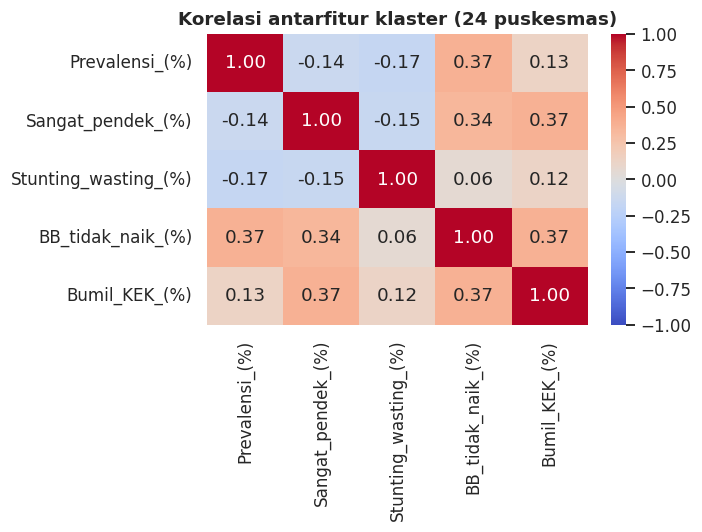

Pasangan fitur dengan |r| >= 0.7: tidak ada
Statistik fitur sebelum standardisasi:


,Prevalensi_(%),Sangat_pendek_(%),Stunting_wasting_(%),BB_tidak_naik_(%),Bumil_KEK_(%)
count,24.00,24.00,24.00,24.00,24.00
mean,3.22,23.11,17.95,39.58,11.61
std,2.45,8.65,7.41,9.85,4.08
min,0.85,12.50,7.40,20.90,2.90
25%,1.59,17.60,12.15,31.98,9.85
50%,2.33,21.85,17.45,42.60,11.05
75%,3.76,26.30,23.20,46.60,12.05
max,10.22,47.90,36.10,55.20,25.40


Statistik fitur setelah StandardScaler (rata-rata ~0, simpangan baku ~1):


,Prevalensi_(%),Sangat_pendek_(%),Stunting_wasting_(%),BB_tidak_naik_(%),Bumil_KEK_(%)
mean,-0.00,-0.00,-0.00,0.00,0.00
std,1.02,1.02,1.02,1.02,1.02



Cek dimensi informasi (PCA): komponen pertama hanya menjelaskan 36% variasi data; butuh 3 komponen untuk mencapai 80% (dari 5 fitur).
-> Informasi tersebar di beberapa sisi, jadi memang perlu lebih dari satu fitur.


In [ ]:
# Seleksi fitur: cek keterkaitan antarfitur (fitur yang terlalu berkaitan = informasi ganda)
korelasi = df_puskesmas[fitur_klaster].corr().round(2)
plt.figure(figsize=(6.5, 5), dpi=110)
sns.heatmap(korelasi, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Korelasi antarfitur klaster (24 puskesmas)', fontweight='bold'); plt.tight_layout(); plt.show()

pasangan = [(a, b, korelasi.loc[a, b]) for i, a in enumerate(fitur_klaster) for b in fitur_klaster[i+1:] if abs(korelasi.loc[a, b]) >= 0.7]
print("Pasangan fitur dengan |r| >= 0.7:", pasangan if pasangan else "tidak ada")
print("Statistik fitur sebelum standardisasi:")
display(df_puskesmas[fitur_klaster].describe().round(2))
print("Statistik fitur setelah StandardScaler (rata-rata ~0, simpangan baku ~1):")
display(pd.DataFrame(X_scaled, columns=fitur_klaster).describe().round(2).loc[['mean', 'std']])

# Apakah 5 fitur memuat lebih dari satu dimensi informasi? (PCA hanya untuk diagnosis dan visual, BUKAN untuk klastering)
var_ratio = PCA().fit(X_scaled).explained_variance_ratio_
n_80 = int(np.argmax(np.cumsum(var_ratio) >= 0.80) + 1)
print(f"\nCek dimensi informasi (PCA): komponen pertama hanya menjelaskan {var_ratio[0]*100:.0f}% variasi data; butuh {n_80} komponen untuk mencapai 80% (dari {len(fitur_klaster)} fitur).")
print("->", "Informasi tersebar di beberapa sisi, jadi memang perlu lebih dari satu fitur." if n_80 >= 2
      else "PERHATIAN: satu sisi mendominasi; kelompok berisiko hanya ditentukan satu indikator.")


In [ ]:
print("Seleksi fitur (ditulis otomatis)\n")
print("Kelima fitur dipakai karena masing-masing mewakili sisi yang berbeda: banyaknya kasus, keparahan, stunting + kurus,")
print("berat badan mandek, dan risiko dari sisi ibu. Rentang nilainya sangat berbeda, jadi skalanya disamakan (standardisasi):")
for f in fitur_klaster:
    print(f"  - {f}: {df_puskesmas[f].min():.2f} sampai {df_puskesmas[f].max():.2f}")
print("\nPasangan fitur yang sangat berkaitan (|r| >= 0,7):", ", ".join(f"{a} & {b} (r={r:.2f})" for a, b, r in pasangan) if pasangan else "tidak ada")
print("Pengaruh membuang satu fitur diuji di Tahap 10d.")


Seleksi fitur (ditulis otomatis)

Kelima fitur dipakai karena masing-masing mewakili sisi yang berbeda: banyaknya kasus, keparahan, stunting + kurus,
berat badan mandek, dan risiko dari sisi ibu. Rentang nilainya sangat berbeda, jadi skalanya disamakan (standardisasi):
  - Prevalensi_(%): 0.85 sampai 10.22
  - Sangat_pendek_(%): 12.50 sampai 47.90
  - Stunting_wasting_(%): 7.40 sampai 36.10
  - BB_tidak_naik_(%): 20.90 sampai 55.20
  - Bumil_KEK_(%): 2.90 sampai 25.40

Pasangan fitur yang sangat berkaitan (|r| >= 0,7): tidak ada
Pengaruh membuang satu fitur diuji di Tahap 10d.


In [ ]:
NAMA_P = {1: 'Prioritas 1 - Urgensi Tertinggi', 2: 'Prioritas 2 - Urgensi Menengah', 3: 'Prioritas 3 - Pemantauan Rutin'}
REKOMENDASI = {   # hipotesis awal, perlu divalidasi Dinkes/ahli gizi
    NAMA_P[1]: 'Usulan: percepatan intervensi (PMT lokal, sweeping penimbangan posyandu), verifikasi kelengkapan pelaporan, dan tinjau indikator yang menonjol pada profil kelompok.',
    NAMA_P[2]: 'Usulan: penguatan pada indikator yang menonjol di profil kelompok (mis. rujukan kasus berat, pemantauan pertumbuhan, intervensi Ibu Hamil KEK).',
    NAMA_P[3]: 'Usulan: pemantauan rutin bulanan di posyandu serta edukasi gizi dan sanitasi keluarga.'
}

def _z(df_fitur, fts=fitur_klaster):
    return (df_fitur[fts] - df_fitur[fts].mean()) / df_fitur[fts].std(ddof=0)

def centroid_z(df_fitur, label, fts=fitur_klaster):
    """z-score rata-rata tiap fitur pada tiap klaster."""
    return _z(df_fitur, fts).reset_index(drop=True).groupby(np.asarray(label)).mean()

def skor_urgensi(df_fitur, label, fts=fitur_klaster):
    return centroid_z(df_fitur, label, fts).mean(axis=1)

def beri_nama_prioritas(df_fitur, label, fts=fitur_klaster):
    """Mengembalikan {id_klaster: nama}. Dipanggil SETELAH klaster terbentuk."""
    urut = skor_urgensi(df_fitur, label, fts).sort_values(ascending=False).index
    return {int(c): NAMA_P[i + 1] for i, c in enumerate(urut)}

def deskripsi_klaster(df_fitur, label, peta, fts=fitur_klaster, batas=0.5):
    """Ciri tiap klaster dalam satuan simpangan baku (SD), dihitung dari data."""
    cz = centroid_z(df_fitur, label, fts); hasil = {}
    for c, nama in peta.items():
        tinggi = [f"{f} ({cz.loc[c, f]:+.1f} SD)" for f in fts if cz.loc[c, f] >= batas]
        rendah = [f"{f} ({cz.loc[c, f]:+.1f} SD)" for f in fts if cz.loc[c, f] <= -batas]
        hasil[nama] = ("tinggi: " + (", ".join(tinggi) or "-")) + " | rendah: " + (", ".join(rendah) or "-")
    return hasil

def sil_aman(Xs, lab):
    return round(silhouette_score(Xs, lab), 3) if len(set(lab)) > 1 else float('nan')


## Tahap 6 - Data Splitting (Membagi Data)

Karena klasterisasi bersifat unsupervised dan jumlah unit analisis terbatas (24 puskesmas), pembagian data acak diganti dengan pengujian konsistensi pola antarbulan:


*   Data Latih: Maret–April 2026 | Data Uji: Mei 2026.
*   Penyelarasan Skala: Menggunakan metode ketat (rata-rata skala data latih) dan relatif (rata-rata data Mei).
*   Catatan: Hasil kecocokan bersifat indikatif karena kelompok pembanding terbentuk dari gabungan tiga bulan penuh (termasuk Mei). Pengujian kestabilan sampel (bootstrap) dibahas pada Tahap 10.









In [ ]:
# beri_nama_prioritas() didefinisikan di sel aturan penamaan (Tahap 5)

latih = hitung_fitur(df_bersih[df_bersih['Bulan'].isin(BULAN_LATIH)].groupby(['Kec', 'Pukesmas']), len(BULAN_LATIH)).sort_values('Puskesmas').reset_index(drop=True)
uji = hitung_fitur(df_bersih[df_bersih['Bulan'] == BULAN_UJI].groupby(['Kec', 'Pukesmas']), 1).sort_values('Puskesmas').reset_index(drop=True)
print(f"Data latih (Maret+April): {len(latih)} puskesmas | Data uji (Mei): {len(uji)} puskesmas")

# Latih HANYA pada Maret-April
sc_latih = StandardScaler().fit(latih[fitur_klaster])
km_latih = KMeans(n_clusters=K, random_state=SEED, n_init=N_INIT).fit(sc_latih.transform(latih[fitur_klaster]))
nama_latih = beri_nama_prioritas(latih, km_latih.labels_)

# Kelompok 'acuan' = hasil model final pada 3 bulan (Tahap 8 akan membentuknya; di sini dihitung ulang dengan parameter yang sama)
km_acuan = KMeans(n_clusters=K, random_state=SEED, n_init=N_INIT).fit(StandardScaler().fit_transform(df_puskesmas[fitur_klaster]))
acuan = pd.Series(km_acuan.labels_, index=df_puskesmas['Puskesmas'])
nama_acuan = beri_nama_prioritas(df_puskesmas, km_acuan.labels_)
acuan_nama = acuan.map(nama_acuan)

def kesepakatan(nama_pred, puskesmas):
    return (pd.Series(nama_pred, index=puskesmas) == acuan_nama.loc[puskesmas]).mean() * 100

# Uji pada Mei: dua cara standardisasi
pred_ketat = km_latih.predict(sc_latih.transform(uji[fitur_klaster]))
pred_relatif = km_latih.predict(StandardScaler().fit_transform(uji[fitur_klaster]))
nama_ketat = pd.Series(pred_ketat).map(nama_latih).values
nama_relatif = pd.Series(pred_relatif).map(nama_latih).values

hasil_split = pd.DataFrame([
    ['Latih (Maret-April), model sendiri', sil_aman(sc_latih.transform(latih[fitur_klaster]), km_latih.labels_),
     round(kesepakatan(pd.Series(km_latih.labels_).map(nama_latih).values, latih['Puskesmas']), 1)],
    ['Uji Mei - standardisasi KETAT (statistik data latih)', sil_aman(sc_latih.transform(uji[fitur_klaster]), pred_ketat),
     round(kesepakatan(nama_ketat, uji['Puskesmas']), 1)],
    ['Uji Mei - standardisasi RELATIF (statistik Mei sendiri)', sil_aman(StandardScaler().fit_transform(uji[fitur_klaster]), pred_relatif),
     round(kesepakatan(nama_relatif, uji['Puskesmas']), 1)],
], columns=['Skenario', 'Silhouette', 'Kesepakatan nama kelompok vs acuan 3 bulan (%)'])
display(hasil_split)

# Mengapa cara ketat jatuh? Cek pergeseran rata-rata fitur Mei vs Maret-April
geser = pd.DataFrame({'Rerata Maret-April': latih[fitur_klaster].mean().round(2), 'Rerata Mei': uji[fitur_klaster].mean().round(2)})
geser['Selisih'] = (geser['Rerata Mei'] - geser['Rerata Maret-April']).round(2)
geser['Selisih (x simpangan baku antar-puskesmas)'] = (geser['Selisih'] / latih[fitur_klaster].std()).round(2)
print("\nPergeseran level fitur dari Maret-April ke Mei:")
display(geser)

# Pembanding independen: pengelompokan Mei sendiri (tidak memuat data latih Maret-April)
lab_mei_sendiri = KMeans(K, n_init=N_INIT, random_state=SEED).fit_predict(StandardScaler().fit_transform(uji[fitur_klaster]))
ari_mei_ketat = adjusted_rand_score(lab_mei_sendiri, pred_ketat)
ari_mei_relatif = adjusted_rand_score(lab_mei_sendiri, pred_relatif)


Data latih (Maret+April): 24 puskesmas | Data uji (Mei): 24 puskesmas


,Skenario,Silhouette,Kesepakatan nama kelompok vs acuan 3 bulan (%)
0,"Latih (Maret-April), model sendiri",0.222,83.3
1,Uji Mei - standardisasi KETAT (statistik data ...,0.081,58.3
2,Uji Mei - standardisasi RELATIF (statistik Mei...,0.198,91.7



Pergeseran level fitur dari Maret-April ke Mei:


,Rerata Maret-April,Rerata Mei,Selisih,Selisih (x simpangan baku antar-puskesmas)
Prevalensi_(%),3.15,3.36,0.21,0.08
Sangat_pendek_(%),24.92,20.96,-3.96,-0.46
Stunting_wasting_(%),19.45,16.71,-2.74,-0.35
BB_tidak_naik_(%),34.52,46.51,11.99,0.97
Bumil_KEK_(%),11.61,11.61,0.00,0.00


In [ ]:
print("Cara membaca hasil uji pada bulan Mei (ditulis otomatis)\n")
r = hasil_split
kt, rl = r.iloc[1, 2], r.iloc[2, 2]
print(f"- Pada data latih, nama kelompok dari model sama dengan kelompok pembanding 3 bulan sebesar {r.iloc[0, 2]}%.")
print(f"- Mei, skala CARA KETAT (memakai rata-rata data latih): kecocokan {kt}%, silhouette {r.iloc[1, 1]}.")
print(f"- Mei, skala CARA RELATIF (memakai rata-rata Mei sendiri): kecocokan {rl}%, silhouette {r.iloc[2, 1]}.")
sel = geser['Selisih (x simpangan baku antar-puskesmas)']; fm = sel.abs().idxmax()
print(f"- Indikator yang paling bergeser dari Maret-April ke Mei: {fm} ({geser.loc[fm, 'Rerata Maret-April']} -> {geser.loc[fm, 'Rerata Mei']}, {sel[fm]:+.2f} SD).")
if rl - kt >= 10:
    print("-> Cara relatif jauh lebih cocok: model mengenali URUTAN relatif antarpuskesmas, tetapi level mutlak indikator ikut bergeser antarbulan.")
    print("   Maka data bulan baru (Tahap 12) disamakan skalanya dengan cara relatif.")
elif kt - rl >= 10:
    print("-> Cara ketat lebih cocok: level indikator relatif stabil antarbulan, jadi rata-rata data latih masih bisa dipakai.")
else:
    print("-> Kedua cara memberi hasil serupa (selisih kurang dari 10 poin).")
print("   CATATAN: kelompok pembanding dibuat dari 3 bulan yang MEMUAT bulan uji, jadi kecocokan di atas cenderung terlalu bagus (bukan bukti independen).")
print("   Dengan hanya 24 puskesmas dan satu bulan uji, angka ini hanya indikasi.")

print(f"- Pembanding independen (ARI prediksi model Maret-April vs pengelompokan Mei sendiri): ketat {ari_mei_ketat:.2f} | relatif {ari_mei_relatif:.2f}.")


Cara membaca hasil uji pada bulan Mei (ditulis otomatis)

- Pada data latih, nama kelompok dari model sama dengan kelompok pembanding 3 bulan sebesar 83.3%.
- Mei, skala CARA KETAT (memakai rata-rata data latih): kecocokan 58.3%, silhouette 0.081.
- Mei, skala CARA RELATIF (memakai rata-rata Mei sendiri): kecocokan 91.7%, silhouette 0.198.
- Indikator yang paling bergeser dari Maret-April ke Mei: BB_tidak_naik_(%) (34.52 -> 46.51, +0.97 SD).
-> Cara relatif jauh lebih cocok: model mengenali URUTAN relatif antarpuskesmas, tetapi level mutlak indikator ikut bergeser antarbulan.
   Maka data bulan baru (Tahap 12) disamakan skalanya dengan cara relatif.
   CATATAN: kelompok pembanding dibuat dari 3 bulan yang MEMUAT bulan uji, jadi kecocokan di atas cenderung terlalu bagus (bukan bukti independen).
   Dengan hanya 24 puskesmas dan satu bulan uji, angka ini hanya indikasi.
- Pembanding independen (ARI prediksi model Maret-April vs pengelompokan Mei sendiri): ketat 0.15 | relatif 0.78.


## Tahap 7 - Model Selection (Memilih Algoritma)

Membandingkan tiga kandidat algoritma pengelompokan ($K=3$): K-Means, Hierarchical (ward), dan GMM (DBSCAN tidak digunakan karena jumlah titik data terlalu sedikit, yaitu 24 puskesmas).Aturan Pemilihan: Model dipilih berdasarkan skor Silhouette tertinggi dengan syarat setiap kelompok berisi minimal 3 puskesmas agar relevan untuk kebijakan penentuan tingkat prioritas Dinas Kesehatan.

In [ ]:
# GMM: pilih tipe kovarians dengan BIC terendah (24 data x 5 fitur: tipe 'full' punya sekitar 62 parameter, terlalu banyak)
bic_gmm = {}
for ct in ['spherical', 'diag', 'tied', 'full']:
    g = GaussianMixture(3, covariance_type=ct, n_init=N_INIT, random_state=SEED).fit(X_scaled)
    bic_gmm[ct] = round(g.bic(X_scaled), 1)
ct_terbaik = min(bic_gmm, key=bic_gmm.get)
print("BIC GMM per tipe kovarians:", bic_gmm, "-> dipakai:", ct_terbaik)

kandidat = {'K-Means': KMeans(K, n_init=N_INIT, random_state=SEED),
            'Hierarchical (ward)': AgglomerativeClustering(3, linkage='ward'),
            f'GMM ({ct_terbaik})': GaussianMixture(3, covariance_type=ct_terbaik, n_init=N_INIT, random_state=SEED)}

label_kandidat = {nm: m.fit_predict(X_scaled) for nm, m in kandidat.items()}
baris = []
for nm, lab in label_kandidat.items():
    ukuran = sorted(np.bincount(lab).tolist(), reverse=True)
    baris.append({'Model': nm, 'Silhouette': round(silhouette_score(X_scaled, lab), 3),
                  'DBI (rendah=baik)': round(davies_bouldin_score(X_scaled, lab), 3),
                  'CHI': round(calinski_harabasz_score(X_scaled, lab), 2),
                  'Ukuran klaster': ukuran, 'Klaster_terkecil': min(ukuran),
                  'ARI vs K-Means': round(adjusted_rand_score(label_kandidat['K-Means'], lab), 3)})
tabel_model = pd.DataFrame(baris)
tabel_model['Memenuhi syarat (min 3/klaster)'] = tabel_model['Klaster_terkecil'] >= 3
display(tabel_model.drop(columns='Klaster_terkecil'))

layak = tabel_model[tabel_model['Klaster_terkecil'] >= 3].sort_values('Silhouette', ascending=False)
if layak.empty:
    print('PERHATIAN: tidak ada model dengan semua klaster >= 3 puskesmas; K-Means dipakai sebagai acuan.')
    layak = tabel_model[tabel_model['Model'] == 'K-Means']
# Selisih Silhouette < TOL_SIL dianggap seri; pemenang seri ditentukan DBI terendah
TOL_SIL = 0.02
seri = layak[layak['Silhouette'] >= layak['Silhouette'].max() - TOL_SIL].sort_values('DBI (rendah=baik)')
layak = pd.concat([seri, layak.drop(seri.index)])
model_terpilih = layak.iloc[0]['Model']
print(f"\nModel terpilih menurut aturan: {model_terpilih} (Silhouette {layak.iloc[0]['Silhouette']})")
dibuang = tabel_model[(tabel_model['Klaster_terkecil'] < 3) & (tabel_model['Silhouette'] > layak.iloc[0]['Silhouette'])]
if len(dibuang):
    print("Model dengan Silhouette lebih tinggi tetapi DIGUGURKAN karena ada klaster berisi < 3 puskesmas:", ", ".join(dibuang['Model']))

# Cek ketahanan aturan: jika syarat dilonggarkan menjadi minimal 2 puskesmas/klaster, apakah pemenangnya berubah?
longgar = tabel_model[tabel_model['Klaster_terkecil'] >= 2].sort_values('Silhouette', ascending=False)
if longgar.empty: longgar = layak
print(f"Jika syarat dilonggarkan (min 2/klaster), pemenang: {longgar.iloc[0]['Model']} (Silhouette {longgar.iloc[0]['Silhouette']})")


BIC GMM per tipe kovarians: {'spherical': np.float64(301.5), 'diag': np.float64(314.6), 'tied': np.float64(383.0), 'full': np.float64(293.6)} -> dipakai: full


,Model,Silhouette,DBI (rendah=baik),CHI,Ukuran klaster,ARI vs K-Means,Memenuhi syarat (min 3/klaster)
0,K-Means,0.268,1.234,8.59,"[14, 6, 4]",1.000,True
1,Hierarchical (ward),0.200,1.317,7.42,"[13, 9, 2]",0.244,False
2,GMM (full),0.279,1.055,4.69,"[20, 3, 1]",0.319,False



Model terpilih menurut aturan: K-Means (Silhouette 0.268)
Model dengan Silhouette lebih tinggi tetapi DIGUGURKAN karena ada klaster berisi < 3 puskesmas: GMM (full)
Jika syarat dilonggarkan (min 2/klaster), pemenang: K-Means (Silhouette 0.268)


In [ ]:
print("Keputusan memilih model (ditulis otomatis)\n")
km_row = tabel_model[tabel_model['Model'] == 'K-Means'].iloc[0]
n_ok = int(tabel_model['Memenuhi syarat (min 3/klaster)'].sum())
print(f"- {n_ok} dari {len(tabel_model)} model memenuhi syarat minimal 3 puskesmas per kelompok.")
print("- Selisih Silhouette kurang dari 0,02 dianggap seri dan diputuskan oleh DBI terendah; GMM diuji pada 4 tipe kovarians (dipilih BIC terendah).")
print(f"- Model terpilih menurut aturan: {model_terpilih} (Silhouette {layak.iloc[0]['Silhouette']}, ukuran kelompok {layak.iloc[0]['Ukuran klaster']}).")
print(f"- K-Means: Silhouette {km_row['Silhouette']}, DBI {km_row['DBI (rendah=baik)']}, ukuran kelompok {km_row['Ukuran klaster']}.")
if len(dibuang):
    print("- Gugur walau Silhouette lebih tinggi (ada kelompok berisi kurang dari 3 puskesmas): " + "; ".join(f"{m} {u}" for m, u in zip(dibuang['Model'], dibuang['Ukuran klaster'])))
print(f"- Kalau syarat dilonggarkan (minimal 2 per kelompok), pemenangnya: {longgar.iloc[0]['Model']}.")
if model_terpilih == 'K-Means':
    print("-> K-Means dipakai sebagai model final: unggul menurut aturan, pusat kelompoknya mudah dibaca, dan mudah dipakai di aplikasi web.")
else:
    print(f"-> PERHATIAN: {model_terpilih} unggul menurut aturan (selisih Silhouette {layak.iloc[0]['Silhouette'] - km_row['Silhouette']:+.3f}). "
          "K-Means tetap dipakai karena aplikasi DSS membutuhkan pusat kelompok dan fungsi predict(). Laporkan selisih ini apa adanya.")
print("- Hierarchical (ward) tetap dilatih sebagai pembanding di Tahap 8.")


Keputusan memilih model (ditulis otomatis)

- 1 dari 3 model memenuhi syarat minimal 3 puskesmas per kelompok.
- Selisih Silhouette kurang dari 0,02 dianggap seri dan diputuskan oleh DBI terendah; GMM diuji pada 4 tipe kovarians (dipilih BIC terendah).
- Model terpilih menurut aturan: K-Means (Silhouette 0.268, ukuran kelompok [14, 6, 4]).
- K-Means: Silhouette 0.268, DBI 1.234, ukuran kelompok [14, 6, 4].
- Gugur walau Silhouette lebih tinggi (ada kelompok berisi kurang dari 3 puskesmas): GMM (full) [20, 3, 1]
- Kalau syarat dilonggarkan (minimal 2 per kelompok), pemenangnya: K-Means.
-> K-Means dipakai sebagai model final: unggul menurut aturan, pusat kelompoknya mudah dibaca, dan mudah dipakai di aplikasi web.
- Hierarchical (ward) tetap dilatih sebagai pembanding di Tahap 8.


## Tahap 8 - Model Training (Melatih Model)

Melatih model final K-Means ($K=3$) menggunakan 5 fitur terstandardisasi (rata-rata 3 bulan) untuk mengelompokkan 24 puskesmas dan menetapkan kategori prioritasnya. Model Hierarchical (Ward) juga dilatih sebagai pembanding.

In [ ]:
# 2. Model final K=3 (K-Means) dan pembanding Ward. Tidak ada label yang dipakai.
kmeans_model = KMeans(n_clusters=K, random_state=SEED, n_init=N_INIT)
df_puskesmas['Cluster_ID'] = kmeans_model.fit_predict(X_scaled)
df_puskesmas['Ward_ID'] = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_scaled)

# 3. Penamaan SETELAH klaster terbentuk (aturan skor urgensi, bobot sama)
peta_prioritas = beri_nama_prioritas(df_puskesmas, df_puskesmas['Cluster_ID'])
df_puskesmas['Kelompok_Prioritas'] = df_puskesmas['Cluster_ID'].map(peta_prioritas)
df_puskesmas['Skor_Urgensi'] = _z(df_puskesmas).mean(axis=1).round(2)   # info tambahan untuk peringkat dalam kelompok; BUKAN dipakai membentuk klaster

# 4. Tabel transparansi: z-score pusat klaster per fitur, skor urgensi, dan nama
cz = centroid_z(df_puskesmas, df_puskesmas['Cluster_ID'])
tabel_nama = cz.round(2).copy()
tabel_nama['Skor_Urgensi_Klaster'] = tabel_nama.mean(axis=1).round(2)
tabel_nama['Jml_Puskesmas'] = df_puskesmas['Cluster_ID'].value_counts().sort_index()
tabel_nama['Nama_Kelompok'] = [peta_prioritas[c] for c in tabel_nama.index]
print("=== MENGAPA KLASTER DINAMAI DEMIKIAN? (z-score pusat klaster; positif = di atas rata-rata = lebih buruk) ===")
display(tabel_nama.sort_values('Nama_Kelompok'))
for nama, teks in deskripsi_klaster(df_puskesmas, df_puskesmas['Cluster_ID'], peta_prioritas).items():
    print(f"- {nama}: {teks}")
p1_id = [c for c, n in peta_prioritas.items() if n == NAMA_P[1]][0]
print(f"\nKesimpulan: klaster {p1_id} menjadi Prioritas 1 karena prevalensi pusatnya paling tinggi ({cz.loc[p1_id, 'Prevalensi_(%)']:+.2f} SD). Prioritas 2 = klaster dengan keparahan dan risiko ibu (4 indikator lain) tertinggi di antara sisanya.")

# Catatan penting: klaster Prioritas 2 menonjol pada keparahan dan risiko ibu, bukan prevalensi
c2_id = [c for c, n in peta_prioritas.items() if n == NAMA_P[2]][0]
print(f"\nCatatan: Prioritas 2 memiliki prevalensi pusat {cz.loc[c2_id, 'Prevalensi_(%)']:+.2f} SD (kasus per sasaran relatif rendah) tetapi keparahan dan risiko ibu tinggi.")
print("Persentase keparahan dihitung dari jumlah kasus yang kecil di beberapa puskesmas, jadi cek apakah pelaporan kasus sudah lengkap (lihat EDA).")

=== MENGAPA KLASTER DINAMAI DEMIKIAN? (z-score pusat klaster; positif = di atas rata-rata = lebih buruk) ===


,Prevalensi_(%),Sangat_pendek_(%),Stunting_wasting_(%),BB_tidak_naik_(%),Bumil_KEK_(%),Skor_Urgensi_Klaster,Jml_Puskesmas,Nama_Kelompok
1,-0.59,1.58,0.33,1.18,1.16,0.73,4,Prioritas 1 - Urgensi Tertinggi
0,1.52,-0.32,-0.05,0.67,0.34,0.43,6,Prioritas 2 - Urgensi Menengah
2,-0.48,-0.32,-0.07,-0.62,-0.48,-0.39,14,Prioritas 3 - Pemantauan Rutin


- Prioritas 1 - Urgensi Tertinggi: tinggi: Sangat_pendek_(%) (+1.6 SD), BB_tidak_naik_(%) (+1.2 SD), Bumil_KEK_(%) (+1.2 SD) | rendah: Prevalensi_(%) (-0.6 SD)
- Prioritas 2 - Urgensi Menengah: tinggi: Prevalensi_(%) (+1.5 SD), BB_tidak_naik_(%) (+0.7 SD) | rendah: -
- Prioritas 3 - Pemantauan Rutin: tinggi: - | rendah: BB_tidak_naik_(%) (-0.6 SD)

Kesimpulan: klaster 1 menjadi Prioritas 1 karena prevalensi pusatnya paling tinggi (-0.59 SD). Prioritas 2 = klaster dengan keparahan dan risiko ibu (4 indikator lain) tertinggi di antara sisanya.

Catatan: Prioritas 2 memiliki prevalensi pusat +1.52 SD (kasus per sasaran relatif rendah) tetapi keparahan dan risiko ibu tinggi.
Persentase keparahan dihitung dari jumlah kasus yang kecil di beberapa puskesmas, jadi cek apakah pelaporan kasus sudah lengkap (lihat EDA).


In [ ]:
# Centroid dalam satuan asli (mudah dibaca) + ukuran kelompok
centroid_asli = pd.DataFrame(scaler.inverse_transform(kmeans_model.cluster_centers_), columns=fitur_klaster).round(2)
centroid_asli.index = [peta_prioritas[i] for i in range(3)]
centroid_asli['Jml_Puskesmas'] = df_puskesmas['Cluster_ID'].value_counts().sort_index().values
display(centroid_asli)


,Prevalensi_(%),Sangat_pendek_(%),Stunting_wasting_(%),BB_tidak_naik_(%),Bumil_KEK_(%),Jml_Puskesmas
Prioritas 2 - Urgensi Menengah,6.86,20.43,17.58,46.05,12.97,6
Prioritas 1 - Urgensi Tertinggi,1.80,36.47,20.32,50.95,16.25,4
Prioritas 3 - Pemantauan Rutin,2.07,20.44,17.42,33.56,9.70,14


## Tahap 9 - Hyperparameter Tuning (Mencari Pengaturan Terbaik)

Menguji nilai $K$ dari 2 hingga 7 pada model K-Means untuk memastikan apakah $K=3$ sudah optimal berdasarkan skor Silhouette dan batas minimum 3 puskesmas per kelompok, sekaligus menguji kestabilan hasil terhadap variasi titik awal acak (seed).

,K,Silhouette,DBI,CHI,Inertia,Klaster_terkecil,ARI_vs_Ward
0,2,0.247,1.563,8.03,87.90,10,0.312
1,3,0.268,1.234,8.59,66.02,4,0.244
2,4,0.243,1.157,8.49,52.79,2,0.525
3,5,0.236,0.878,8.17,44.13,1,0.513
4,6,0.181,0.858,8.41,35.98,1,0.709
5,7,0.190,0.862,8.75,29.36,1,0.423


Catatan: K dengan kelompok terkecil < 3 puskesmas disisihkan lebih dulu oleh aturan ini, dan selisih Silhouette K=2 dan K=3 kecil.
K terbaik (Silhouette tertinggi dengan klaster terkecil >= 3): K = 3
n_init=  1: 6% dari 50 seed menghasilkan pengelompokan identik
n_init= 10: 80% dari 50 seed menghasilkan pengelompokan identik
n_init=200: 100% dari 50 seed menghasilkan pengelompokan identik


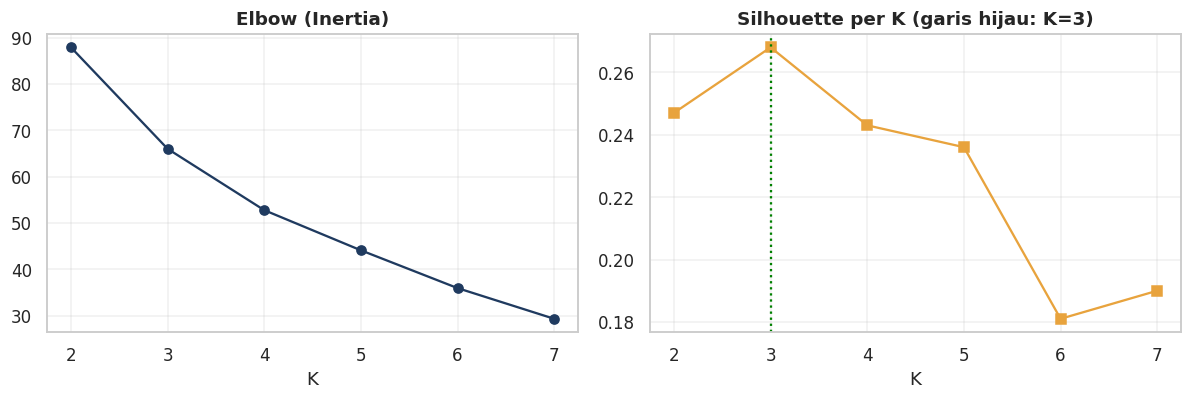

In [ ]:
# Menguji K=2 sampai 7 (K-Means, n_init=200) dan membandingkannya dengan Ward
baris = []
for k in range(2, 8):
    km_k = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X_scaled)
    ward_k = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    baris.append({'K': k, 'Silhouette': round(silhouette_score(X_scaled, km_k.labels_), 3),
                  'DBI': round(davies_bouldin_score(X_scaled, km_k.labels_), 3), 'CHI': round(calinski_harabasz_score(X_scaled, km_k.labels_), 2), 'Inertia': round(km_k.inertia_, 2),
                  'Klaster_terkecil': int(np.bincount(km_k.labels_).min()),
                  'ARI_vs_Ward': round(adjusted_rand_score(km_k.labels_, ward_k), 3)})
ringkas_k = pd.DataFrame(baris)
display(ringkas_k)
print("Catatan: K dengan kelompok terkecil < 3 puskesmas disisihkan lebih dulu oleh aturan ini, dan selisih Silhouette K=2 dan K=3 kecil.")

valid = ringkas_k[ringkas_k['Klaster_terkecil'] >= 3].sort_values('Silhouette', ascending=False)
if valid.empty:
    print('PERHATIAN: tidak ada K dengan klaster terkecil >= 3; K=3 dipakai sebagai acuan.')
    K_terbaik = 3
else:
    K_terbaik = int(valid.iloc[0]['K'])
print(f"K terbaik (Silhouette tertinggi dengan klaster terkecil >= 3): K = {K_terbaik}")

# Kestabilan terhadap seed untuk K final (=3): berapa dari 50 seed menghasilkan pengelompokan yang sama?
acuan_lab = KMeans(K, n_init=N_INIT, random_state=SEED).fit_predict(X_scaled)
hasil_seed = {}
for n_init in [1, 10, 200]:
    ari = [adjusted_rand_score(acuan_lab, KMeans(K, n_init=n_init, random_state=s).fit_predict(X_scaled)) for s in range(50)]
    hasil_seed[n_init] = float(np.mean(np.array(ari) > 0.999) * 100)
    print(f"n_init={n_init:>3}: {hasil_seed[n_init]:.0f}% dari 50 seed menghasilkan pengelompokan identik")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), dpi=110)
ax[0].plot(ringkas_k['K'], ringkas_k['Inertia'], marker='o', color='#1f3a5f'); ax[0].set_title('Elbow (Inertia)', fontweight='bold'); ax[0].set_xlabel('K')
ax[1].plot(ringkas_k['K'], ringkas_k['Silhouette'], marker='s', color='#e8a33d'); ax[1].axvline(3, ls=':', color='green')
ax[1].set_title('Silhouette per K (garis hijau: K=3)', fontweight='bold'); ax[1].set_xlabel('K')
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()


In [ ]:
print("Keputusan tuning (ditulis otomatis)\n")
rk = ringkas_k.set_index('K')
print("- Silhouette tiap K       : " + ", ".join(f"K={k}: {v:.3f}" for k, v in rk['Silhouette'].items()))
print("- Kelompok terkecil tiap K: " + ", ".join(f"K={k}: {int(v)}" for k, v in rk['Klaster_terkecil'].items()))
if K_terbaik == 3:
    print(f"-> K=3 memiliki Silhouette tertinggi di antara K yang kelompok terkecilnya minimal 3 puskesmas, tetapi selisihnya dari K=2 kecil ({rk.loc[3, 'Silhouette']:.3f} vs {rk.loc[2, 'Silhouette']:.3f}) dan inertia tidak menunjukkan siku yang jelas.")
    print("   K=3 dipilih terutama karena kebutuhan tiga tingkat prioritas Dinkes; data tidak menunjukkan jumlah kelompok optimal yang tegas.")
else:
    print(f"-> PERHATIAN: data lebih mendukung K={K_terbaik} (Silhouette {rk.loc[K_terbaik, 'Silhouette']:.3f}) daripada K=3 ({rk.loc[3, 'Silhouette']:.3f}).")
    print("   K=3 tetap dipakai karena kebutuhan tiga tingkat prioritas Dinkes. Laporkan selisih ini apa adanya.")
print("- Ketahanan terhadap seed: " + "; ".join(f"n_init={n}: {v:.0f}% seed menghasilkan kelompok yang sama" for n, v in hasil_seed.items()))
print("- Kurva Elbow dibaca bersama Silhouette. Kalau tidak ada siku yang tajam, kegunaan kelompok untuk kebijakan jadi dasar utama.")


Keputusan tuning (ditulis otomatis)

- Silhouette tiap K       : K=2: 0.247, K=3: 0.268, K=4: 0.243, K=5: 0.236, K=6: 0.181, K=7: 0.190
- Kelompok terkecil tiap K: K=2: 10, K=3: 4, K=4: 2, K=5: 1, K=6: 1, K=7: 1
-> K=3 memiliki Silhouette tertinggi di antara K yang kelompok terkecilnya minimal 3 puskesmas, tetapi selisihnya dari K=2 kecil (0.268 vs 0.247) dan inertia tidak menunjukkan siku yang jelas.
   K=3 dipilih terutama karena kebutuhan tiga tingkat prioritas Dinkes; data tidak menunjukkan jumlah kelompok optimal yang tegas.
- Ketahanan terhadap seed: n_init=1: 6% seed menghasilkan kelompok yang sama; n_init=10: 80% seed menghasilkan kelompok yang sama; n_init=200: 100% seed menghasilkan kelompok yang sama
- Kurva Elbow dibaca bersama Silhouette. Kalau tidak ada siku yang tajam, kegunaan kelompok untuk kebijakan jadi dasar utama.


## Tahap 10 - Model Evaluation (Menilai Hasil)

Karena klasterisasi tidak memiliki label kebenaran (ground truth), validasi dilakukan dari 8 aspek pengujian:
1. skor internal,
2. perbandingan terhadap data acak,
3. konsistensi antaralgoritma,
4. stabilitas antarbulan,
5. bootstrap,
6. sensitivitas desain,
7. uji satu dimensi, dan
8. tingkat keyakinan per puskesmas, disertai analisis derau angka kecil (10f), interval peringkat (10g), serta profil kelompok (10i). Seluruh temuan dirangkum dalam kartu skor evaluasi di akhir tahap ini.

### 10a - Skor internal model final

Silhouette mengukur seberapa jelas puskesmas lebih dekat ke kelompoknya sendiri daripada ke kelompok lain (maksimum 1). Patokan praktis: di bawah 0,25 lemah, 0,25-0,5 sedang, di atas 0,5 tegas.

In [ ]:
lab_final = df_puskesmas['Cluster_ID'].to_numpy()
sil_final = silhouette_score(X_scaled, lab_final); dbi_final = davies_bouldin_score(X_scaled, lab_final); chi_final = calinski_harabasz_score(X_scaled, lab_final)
print(f"Silhouette: {sil_final:.3f} | Davies-Bouldin: {dbi_final:.3f} | Calinski-Harabasz: {chi_final:.2f}")
print("Patokan Kaufman & Rousseeuw (1990): 0,26-0,50 = struktur lemah (bisa saja buatan); 0,51-0,70 = cukup; di atas 0,70 = kuat. Nilai ini harus dilaporkan sebagai batasan.")

df_puskesmas['Silhouette_sampel'] = silhouette_samples(X_scaled, lab_final).round(3)
print("\nPuskesmas yang lebih cocok dengan kelompok lain (silhouette negatif = di perbatasan):")
display(df_puskesmas.loc[df_puskesmas['Silhouette_sampel'] < 0, ['Puskesmas', 'Kelompok_Prioritas', 'Silhouette_sampel']]
        if (df_puskesmas['Silhouette_sampel'] < 0).any() else "Tidak ada")


Silhouette: 0.268 | Davies-Bouldin: 1.234 | Calinski-Harabasz: 8.59
Patokan Kaufman & Rousseeuw (1990): 0,26-0,50 = struktur lemah (bisa saja buatan); 0,51-0,70 = cukup; di atas 0,70 = kuat. Nilai ini harus dilaporkan sebagai batasan.

Puskesmas yang lebih cocok dengan kelompok lain (silhouette negatif = di perbatasan):


,Puskesmas,Kelompok_Prioritas,Silhouette_sampel
13,LUBUK KILANGAN,Prioritas 1 - Urgensi Tertinggi,-0.225


### 10a-2 - Apakah lebih baik dari data acak? (uji permutasi)

Kolom-kolom data diacak sehingga hubungan antarindikator hilang. Kalau hasil asli tidak lebih baik dari hasil acak, kelompoknya bisa jadi hanya kebetulan.

Silhouette asli: 0.268 | data teracak: rerata 0.229, persentil 95 = 0.296
Nilai p (proporsi hasil acak >= asli): 0.146
-> PERHATIAN: kelompok tidak jelas lebih baik dari data acak.
Catatan: lolos uji ini hanya berarti ada pola, belum membuktikan ada kelompok alami yang tegas.


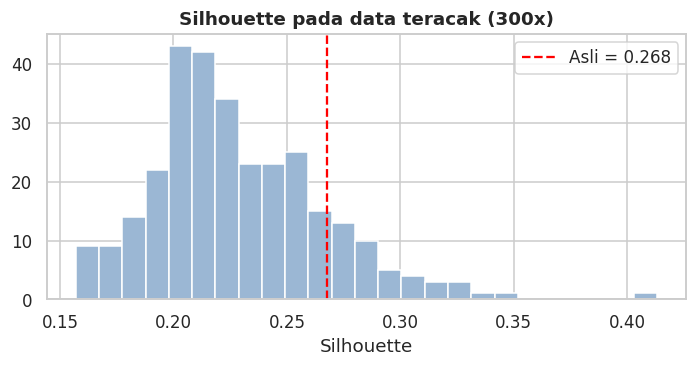

In [ ]:
# Setiap kolom fitur diacak sendiri-sendiri (hubungan antarfitur dihancurkan, sebaran tiap fitur tetap), lalu di-K-Means dan diukur Silhouette-nya.
# Jika Silhouette asli tidak melebihi sebagian besar hasil acak, struktur klaster tidak bisa dibedakan dari kebetulan.
rng_p = np.random.default_rng(0)
sil_perm = []
for _ in range(300):
    Xp = np.column_stack([rng_p.permutation(X_scaled[:, j]) for j in range(X_scaled.shape[1])])
    sil_perm.append(silhouette_score(Xp, KMeans(K, n_init=N_INIT, random_state=0).fit_predict(Xp)))
sil_perm = np.array(sil_perm)
p_perm = float((1 + (sil_perm >= sil_final).sum()) / (len(sil_perm) + 1))   # koreksi (1+hitung)/(B+1)
print(f"Silhouette asli: {sil_final:.3f} | data teracak: rerata {sil_perm.mean():.3f}, persentil 95 = {np.percentile(sil_perm, 95):.3f}")
print(f"Nilai p (proporsi hasil acak >= asli): {p_perm:.3f}")
print("->", "Kelompok lebih baik dari data acak." if p_perm < 0.05 else "PERHATIAN: kelompok tidak jelas lebih baik dari data acak.")
print("Catatan: lolos uji ini hanya berarti ada pola, belum membuktikan ada kelompok alami yang tegas.")
plt.figure(figsize=(6.5, 3.5), dpi=110)
plt.hist(sil_perm, bins=25, color='#9bb7d4', edgecolor='white'); plt.axvline(sil_final, color='red', ls='--', label=f'Asli = {sil_final:.3f}')
plt.title('Silhouette pada data teracak (300x)', fontweight='bold'); plt.xlabel('Silhouette'); plt.legend(); plt.tight_layout(); plt.show()


### 10b - Kestabilan antarbulan

Pengelompokan diulang terpisah untuk tiap bulan, lalu dibandingkan dengan ARI. ARI 1 = sama persis, mendekati 0 = tidak mirip. Patokan praktis: 0,7 ke atas baik, 0,5-0,7 sedang, di bawah 0,5 lemah.

In [ ]:
# Kelompokkan ulang tiap bulan, lalu bandingkan dengan ARI (nomor kelompok antarbulan bebas)
klaster_bulanan = {}
for bln in BULAN:
    sub = agg_bulanan[agg_bulanan['Bulan'] == bln].sort_values('Puskesmas')
    klaster_bulanan[bln] = KMeans(n_clusters=K, random_state=SEED, n_init=N_INIT).fit_predict(
        StandardScaler().fit_transform(sub[fitur_klaster]))
ari_mar_apr = adjusted_rand_score(klaster_bulanan['2026-03'], klaster_bulanan['2026-04'])
ari_apr_mei = adjusted_rand_score(klaster_bulanan['2026-04'], klaster_bulanan['2026-05'])
print(f"ARI Maret-April: {ari_mar_apr:.3f} | April-Mei: {ari_apr_mei:.3f}")
if min(ari_mar_apr, ari_apr_mei) < 0.5:
    print("-> ARI di bawah 0,5 berarti pengelompokan dari satu bulan saja belum stabil. Karena itu dasar kebijakan memakai rata-rata 3 bulan.")
else:
    print("-> ARI 0,5 ke atas: pengelompokan antarbulan cukup konsisten.")


ARI Maret-April: 0.300 | April-Mei: 0.386
-> ARI di bawah 0,5 berarti pengelompokan dari satu bulan saja belum stabil. Karena itu dasar kebijakan memakai rata-rata 3 bulan.


### 10c - Tahan terhadap sampel anak? (bootstrap)

Sampel anak diambil ulang 300 kali, lalu puskesmas dikelompokkan lagi. Kalau hasilnya jarang berubah, keanggotaan kelompok tidak bergantung pada anak tertentu.

In [ ]:
rng = np.random.default_rng(42)
B = 300  # jumlah pengulangan

d = df_bersih[['Pukesmas', 'TB/U', 'BB/TB', 'Naik Berat Badan']].copy()
d['k'] = 1
d['sp'] = (d['TB/U'].astype(str).str.strip() == 'Sangat Pendek').astype(int)
d['sw'] = d['BB/TB'].astype(str).str.strip().isin(['Gizi Kurang', 'Gizi Buruk']).astype(int)
d['bbt'] = (d['Naik Berat Badan'].astype(str).str.strip() == 'T').astype(int)
arr_pusk = {p: g[['k', 'sp', 'sw', 'bbt']].to_numpy() for p, g in d.groupby('Pukesmas')}
daftar_pusk = df_puskesmas['Puskesmas'].tolist()          # urutan sama dengan df_puskesmas
label_asli = df_puskesmas['Cluster_ID'].to_numpy()

def fitur_dari(data_per_pusk):
    baris = []
    for p in daftar_pusk:
        a = data_per_pusk[p]; n_kasus = a[:, 0].sum()
        baris.append([n_kasus / (sasaran_dict[p] * 3) * 100, a[:, 1].sum() / n_kasus * 100,
                      a[:, 2].sum() / n_kasus * 100, a[:, 3].sum() / n_kasus * 100, bumil_kek_dict[p]])
    return pd.DataFrame(baris, columns=fitur_klaster)

def resample(arr_pusk, rng):
    """Resampling anak per puskesmas. Jumlah kasus ikut bervariasi (Poisson), supaya Prevalensi juga memiliki ketidakpastian."""
    out = {}
    for p, a in arr_pusk.items():
        n_b = max(int(rng.poisson(len(a))), 2)
        out[p] = a[rng.integers(0, len(a), n_b)]
    return out

hitung_sama = np.zeros(len(daftar_pusk))
tercatat = [dict() for _ in daftar_pusk]
ari_list = []
for _ in range(B):
    boot = resample(arr_pusk, rng)   # resampling anak per puskesmas; jumlah kasus ikut bervariasi
    Xb = fitur_dari(boot)
    pred = kmeans_model.predict(scaler.transform(Xb))                             # model final tetap
    hitung_sama += (pred == label_asli)
    for i, c in enumerate(pred):
        tercatat[i][c] = tercatat[i].get(c, 0) + 1
    # klaster ulang dari nol pada data bootstrap (label bebas, dibandingkan lewat ARI)
    lab_baru = KMeans(3, n_init=20, random_state=0).fit_predict(StandardScaler().fit_transform(Xb))
    ari_list.append(adjusted_rand_score(label_asli, lab_baru))

kepastian = pd.DataFrame({
    'Puskesmas': daftar_pusk,
    'Kelompok': df_puskesmas['Kelompok_Prioritas'].values,
    'Kepastian_Keanggotaan_(%)': (hitung_sama / B * 100).round(1),
    'Kelompok_Alternatif_Tersering': [
        (peta_prioritas[max((c for c in t if c != label_asli[i]), key=t.get)] if any(c != label_asli[i] for c in t) else '-')
        for i, t in enumerate(tercatat)]
})
kepastian['Status'] = pd.cut(kepastian['Kepastian_Keanggotaan_(%)'], [-0.01, 70, 90, 100.01], right=False,
                             labels=['Perbatasan', 'Cukup kokoh', 'Kokoh'])
print(f"=== BOOTSTRAP ({B}x): APAKAH KEANGGOTAAN KELOMPOK TAHAN? ===")
print(f"Kemiripan (ARI) kelompok hasil ulang vs kelompok asli: rata-rata {np.mean(ari_list):.3f} (rentang {np.min(ari_list):.2f}-{np.max(ari_list):.2f})")
print(f"Puskesmas 'Kokoh' (>=90%): {(kepastian['Status']=='Kokoh').sum()} | 'Cukup kokoh': {(kepastian['Status']=='Cukup kokoh').sum()} | 'Perbatasan' (<70%): {(kepastian['Status']=='Perbatasan').sum()}")
print("Catatan: jumlah kasus tiap puskesmas divariasikan dengan Poisson (asumsi). Batas 70% dan 90% adalah patokan praktis, bukan standar baku. Bootstrap menganggap tiap baris berdiri sendiri,")
print("padahal anak yang sama bisa muncul di beberapa bulan, jadi ketidakpastian sebenarnya bisa sedikit lebih besar.")
display(kepastian.sort_values('Kepastian_Keanggotaan_(%)'))


=== BOOTSTRAP (300x): APAKAH KEANGGOTAAN KELOMPOK TAHAN? ===
Kemiripan (ARI) kelompok hasil ulang vs kelompok asli: rata-rata 0.679 (rentang 0.11-1.00)
Puskesmas 'Kokoh' (>=90%): 23 | 'Cukup kokoh': 1 | 'Perbatasan' (<70%): 0
Catatan: jumlah kasus tiap puskesmas divariasikan dengan Poisson (asumsi). Batas 70% dan 90% adalah patokan praktis, bukan standar baku. Bootstrap menganggap tiap baris berdiri sendiri,
padahal anak yang sama bisa muncul di beberapa bulan, jadi ketidakpastian sebenarnya bisa sedikit lebih besar.


,Puskesmas,Kelompok,Kepastian_Keanggotaan_(%),Kelompok_Alternatif_Tersering,Status
13,LUBUK KILANGAN,Prioritas 1 - Urgensi Tertinggi,84.3,Prioritas 3 - Pemantauan Rutin,Cukup kokoh
3,AMBACANG,Prioritas 3 - Pemantauan Rutin,93.3,Prioritas 1 - Urgensi Tertinggi,Kokoh
16,PARAK KARAKAH,Prioritas 3 - Pemantauan Rutin,96.0,Prioritas 2 - Urgensi Menengah,Kokoh
15,PADANG PASIR,Prioritas 2 - Urgensi Menengah,97.3,Prioritas 1 - Urgensi Tertinggi,Kokoh
7,BUNGUS,Prioritas 1 - Urgensi Tertinggi,98.7,Prioritas 3 - Pemantauan Rutin,Kokoh
23,ULAK KARANG,Prioritas 3 - Pemantauan Rutin,99.3,Prioritas 1 - Urgensi Tertinggi,Kokoh
1,AIR TAWAR,Prioritas 2 - Urgensi Menengah,99.7,Prioritas 3 - Pemantauan Rutin,Kokoh
21,SEBERANG PADANG,Prioritas 2 - Urgensi Menengah,99.7,Prioritas 3 - Pemantauan Rutin,Kokoh
6,BELIMBING,Prioritas 3 - Pemantauan Rutin,100.0,-,Kokoh
5,ANDALAS,Prioritas 3 - Pemantauan Rutin,100.0,-,Kokoh


### 10d - Uji sensitivitas (ubah K atau buang satu indikator)

Satu pilihan desain diubah (jumlah kelompok, atau satu indikator dibuang), lalu dilihat apakah anggota Prioritas 1 tetap bersama.

In [ ]:
varian = {
    'Dasar (5 fitur, K=3)': (fitur_klaster, 3),
    'K=2': (fitur_klaster, 2),
    'K=4': (fitur_klaster, 4),
    'Tanpa Bumil KEK': ([f for f in fitur_klaster if f != 'Bumil_KEK_(%)'], 3),
    'Tanpa Prevalensi': ([f for f in fitur_klaster if f != 'Prevalensi_(%)'], 3),
    '3 indikator keparahan saja': (['Sangat_pendek_(%)', 'Stunting_wasting_(%)', 'BB_tidak_naik_(%)'], 3),
}
p1_set = set(df_puskesmas.loc[df_puskesmas['Kelompok_Prioritas'].str.startswith('Prioritas 1'), 'Puskesmas'])
baris = []
utuh_list = []
for nama, (fts, k) in varian.items():
    Xv = StandardScaler().fit_transform(df_puskesmas[fts])
    lab = KMeans(k, n_init=N_INIT, random_state=SEED).fit_predict(Xv)
    s = pd.Series(lab, index=df_puskesmas['Puskesmas'])
    modal = s[list(p1_set)].mode()[0]
    anggota = set(s[s == modal].index)
    utuh_list.append(len(p1_set & anggota) == len(p1_set))
    baris.append({
        'Varian': nama,
        'Silhouette': round(silhouette_score(Xv, lab), 3),
        'ARI vs dasar': round(adjusted_rand_score(label_asli, lab), 3),
        'Prioritas 1 yang tetap sekelompok': f"{len(p1_set & anggota)}/{len(p1_set)}",
        'Anggota lain di kelompok itu': ", ".join(sorted(anggota - p1_set)) or '-',
    })
tabel_sens = pd.DataFrame(baris)
print("=== UJI SENSITIVITAS ===")
display(tabel_sens)
print("Cara baca: jika 'Prioritas 1 yang tetap sekelompok' tinggi di banyak varian, kelompok prevalensi tinggi cukup kokoh.")
print("Jika rendah di varian tertentu (mis. tanpa prevalensi), itu menunjukkan bahwa kelompok tsb sangat ditentukan oleh fitur itu.")
print(f"\nRingkasan: seluruh anggota Prioritas 1 tetap sekelompok pada {sum(utuh_list)} dari {len(utuh_list)} varian (termasuk varian dasar).")


=== UJI SENSITIVITAS ===


,Varian,Silhouette,ARI vs dasar,Prioritas 1 yang tetap sekelompok,Anggota lain di kelompok itu
0,"Dasar (5 fitur, K=3)",0.268,1.000,4/4,-
1,K=2,0.247,0.826,4/4,"AIR TAWAR, ANAK AIR, IKUR KOTO, PADANG PASIR, ..."
2,K=4,0.243,0.662,2/4,"AMBACANG, BELIMBING, LB.BUAYA"
3,Tanpa Bumil KEK,0.288,1.000,4/4,-
4,Tanpa Prevalensi,0.225,0.451,2/4,"AIR TAWAR, AMBACANG, ANAK AIR, IKUR KOTO, PADA..."
5,3 indikator keparahan saja,0.289,0.257,2/4,"AIR TAWAR, AMBACANG, ANAK AIR, BELIMBING, LB.B..."


Cara baca: jika 'Prioritas 1 yang tetap sekelompok' tinggi di banyak varian, kelompok prevalensi tinggi cukup kokoh.
Jika rendah di varian tertentu (mis. tanpa prevalensi), itu menunjukkan bahwa kelompok tsb sangat ditentukan oleh fitur itu.

Ringkasan: seluruh anggota Prioritas 1 tetap sekelompok pada 3 dari 6 varian (termasuk varian dasar).


### 10e - Apakah hasilnya cuma pengurutan prevalensi?

Kalau pengelompokan memakai prevalensi saja ternyata hasilnya sama, berarti empat indikator lain tidak menambah informasi.

In [ ]:
# Uji satu dimensi: jika hanya prevalensi yang dipakai, apakah kelompoknya sama dengan model 5 fitur?
lab_1d = KMeans(K, n_init=N_INIT, random_state=SEED).fit_predict(StandardScaler().fit_transform(df_puskesmas[['Prevalensi_(%)']]))
ari_1d = adjusted_rand_score(df_puskesmas['Cluster_ID'], lab_1d)
rho_prev = spearmanr(df_puskesmas['Skor_Urgensi'], df_puskesmas['Prevalensi_(%)'])[0]
print("=== UJI SATU DIMENSI ===")
print(f"Klastering hanya dari prevalensi vs model 5 fitur: ARI = {ari_1d:.2f}")
print(f"Korelasi peringkat (Spearman) skor urgensi vs prevalensi: {rho_prev:.2f}")
if ari_1d < 0.7:
    print("-> Model 5 fitur menghasilkan pengelompokan yang berbeda nyata dari pengurutan prevalensi saja; dimensi lain ikut menentukan.")
else:
    print("-> PERHATIAN: hasil mirip pengelompokan prevalensi saja. Laporkan bahwa dimensi lain belum banyak menambah informasi.")

p1_mask = df_puskesmas['Kelompok_Prioritas'].str.startswith('Prioritas 1')
print(f"\nPrioritas 1: prevalensi terendah {df_puskesmas.loc[p1_mask, 'Prevalensi_(%)'].min():.2f}% | kelompok lain: prevalensi tertinggi {df_puskesmas.loc[~p1_mask, 'Prevalensi_(%)'].max():.2f}%")
if df_puskesmas.loc[p1_mask, 'Prevalensi_(%)'].min() > df_puskesmas.loc[~p1_mask, 'Prevalensi_(%)'].max():
    print("-> Prioritas 1 dapat dipisahkan sempurna hanya dengan SATU ambang prevalensi (setara pengurutan).")
else:
    print("-> Prioritas 1 TIDAK identik dengan puskesmas berprevalensi tertinggi; indikator keparahan dan risiko ibu ikut menentukan.")
if df_puskesmas.loc[p1_mask, 'Prevalensi_(%)'].min() > df_puskesmas.loc[~p1_mask, 'Prevalensi_(%)'].max():
    print("   Nilai tambah indikator lain terutama ada pada pemisahan Prioritas 2 (keparahan dan risiko ibu) dari Prioritas 3.")

=== UJI SATU DIMENSI ===
Klastering hanya dari prevalensi vs model 5 fitur: ARI = 0.41
Korelasi peringkat (Spearman) skor urgensi vs prevalensi: 0.41
-> Model 5 fitur menghasilkan pengelompokan yang berbeda nyata dari pengurutan prevalensi saja; dimensi lain ikut menentukan.

Prioritas 1: prevalensi terendah 0.85% | kelompok lain: prevalensi tertinggi 10.22%
-> Prioritas 1 TIDAK identik dengan puskesmas berprevalensi tertinggi; indikator keparahan dan risiko ibu ikut menentukan.


### 10f - Tambahan: apakah angka kasus kecil menimbulkan "derau"? (opsional)

Memeriksa apakah variasi persentase puskesmas dengan sedikit kasus disebabkan oleh faktor kebetulan (fluktuasi sampel kecil), menggunakan koreksi empiris untuk memastikan model akhir tidak bias.

In [ ]:
def eb_koreksi(sukses, n):
    """Menarik proporsi puskesmas berkasus sedikit mendekati rata-rata umum (metode Empirical Bayes). Mengembalikan (proporsi terkoreksi, reliabilitas).
    Tiap pengamatan dianggap berdiri sendiri, padahal anak yang sama bisa muncul di beberapa bulan."""
    sukses = np.asarray(sukses, float); n = np.asarray(n, float); ok = n > 0
    n_aman = np.where(ok, n, 1.0)
    p_hat = np.where(ok, sukses / n_aman, np.nan)
    p0 = np.nansum(p_hat * n) / n[ok].sum()
    var_obs = np.nanvar(p_hat, ddof=1)
    var_derau = np.where(ok, p0 * (1 - p0) / n_aman, np.inf)
    var_sinyal = max(var_obs - np.mean(var_derau[ok]), 0.0)
    reliabilitas = var_sinyal / var_obs if var_obs > 0 else 0.0
    w = var_sinyal / (var_sinyal + var_derau) if var_sinyal > 0 else np.zeros_like(n)
    return np.where(ok, p0 + w * (np.nan_to_num(p_hat) - p0), p0), reliabilitas

def koreksi_tabel(agg, jml_bulan):
    out = agg[fitur_klaster].astype(float).copy(); rel = {}
    spes = {'Prevalensi_(%)':       (agg['Total_Kasus'], agg['Sasaran_balita_per_bulan'] * jml_bulan),
            'Sangat_pendek_(%)':    (agg['Total_SP'], agg['Total_Kasus']),
            'Stunting_wasting_(%)': (agg['Total_SW'], agg['Total_Kasus']),
            'BB_tidak_naik_(%)':    (agg['Total_BBT'], agg['Total_Kasus'])}
    for f, (k, n) in spes.items():
        p, r = eb_koreksi(k.to_numpy(), n.to_numpy()); out[f] = p * 100; rel[f] = r
    return out, rel      # Bumil_KEK_(%) tidak diubah: rekap Dinkes, bukan hitungan BNBA

X_koreksi, rel_fitur = koreksi_tabel(df_puskesmas, 3)
print("=== RELIABILITAS FITUR (data 3 bulan) ===")
for f, r in rel_fitur.items():
    print(f"- {f}: {r:.2f} -> " + ("sinyal dominan" if r >= .7 else ("campuran sinyal dan derau" if r >= .4 else "sebagian besar derau")))
print("- Bumil_KEK_(%): rekap Dinkes (bukan hitungan BNBA), tidak dikoreksi.")

Zk = StandardScaler().fit_transform(X_koreksi)
lab_koreksi = KMeans(K, n_init=N_INIT, random_state=SEED).fit_predict(Zk)
ari_koreksi = adjusted_rand_score(df_puskesmas['Cluster_ID'], lab_koreksi)
print(f"\nKemiripan kelompok dari fitur terkoreksi vs asli (ARI) = {ari_koreksi:.2f} | Silhouette terkoreksi = {sil_aman(Zk, lab_koreksi)} (asli {sil_final:.3f})")

# Apakah derau menjelaskan lemahnya kestabilan antarbulan? Ulangi uji 10b dengan fitur terkoreksi.
bln = sorted(klaster_bulanan)
lab_bln_kor = {}; rel_bulanan = []
for b in bln:
    sub = agg_bulanan[agg_bulanan['Bulan'] == b].sort_values('Puskesmas').reset_index(drop=True)
    Xk, rel_b = koreksi_tabel(sub, 1); rel_bulanan.append(float(np.mean(list(rel_b.values()))))
    lab_bln_kor[b] = KMeans(K, n_init=N_INIT, random_state=SEED).fit_predict(StandardScaler().fit_transform(Xk))
ari_kor_1 = adjusted_rand_score(lab_bln_kor[bln[0]], lab_bln_kor[bln[1]])
ari_kor_2 = adjusted_rand_score(lab_bln_kor[bln[1]], lab_bln_kor[bln[2]])
asli_rata, kor_rata = np.mean([ari_mar_apr, ari_apr_mei]), np.mean([ari_kor_1, ari_kor_2])
print(f"ARI antarbulan | asli: {ari_mar_apr:.2f} / {ari_apr_mei:.2f} | terkoreksi: {ari_kor_1:.2f} / {ari_kor_2:.2f}")
rel_rata = float(np.mean(rel_bulanan))   # reliabilitas data BULANAN (yang diuji di 10b), bukan data 3 bulan
print(f"Reliabilitas rata-rata data bulanan: {rel_rata:.2f} (data 3 bulan: {np.mean(list(rel_fitur.values())):.2f})")
if rel_rata < .4:
    diag_derau = f"sebagian besar perbedaan antarpuskesmas pada indikator BNBA hanyalah kebetulan angka kecil (reliabilitas rata-rata {rel_rata:.2f}); koreksi tidak bisa menciptakan sinyal yang tidak ada"
elif kor_rata - asli_rata >= .15:
    diag_derau = f"angka kasus kecil ikut melemahkan kestabilan antarbulan (ARI rata-rata naik dari {asli_rata:.2f} ke {kor_rata:.2f} setelah dikoreksi; reliabilitas rata-rata {rel_rata:.2f})"
else:
    diag_derau = f"indikator cukup andal (reliabilitas rata-rata {rel_rata:.2f}) dan koreksi tidak banyak mengubah kestabilan antarbulan ({asli_rata:.2f} -> {kor_rata:.2f}); jadi lemahnya kestabilan kemungkinan karena pola yang memang berubah antarbulan, bukan karena angka kecil"
print("\n->", diag_derau[0].upper() + diag_derau[1:] + ".")
print("   Model final tetap memakai fitur asli. Kalau angka kecil berperan, obat terbaiknya adalah menambah bulan data.")


=== RELIABILITAS FITUR (data 3 bulan) ===
- Prevalensi_(%): 0.99 -> sinyal dominan
- Sangat_pendek_(%): 0.79 -> sinyal dominan
- Stunting_wasting_(%): 0.78 -> sinyal dominan
- BB_tidak_naik_(%): 0.78 -> sinyal dominan
- Bumil_KEK_(%): rekap Dinkes (bukan hitungan BNBA), tidak dikoreksi.

Kemiripan kelompok dari fitur terkoreksi vs asli (ARI) = 1.00 | Silhouette terkoreksi = 0.272 (asli 0.268)
ARI antarbulan | asli: 0.30 / 0.39 | terkoreksi: 0.27 / 0.27
Reliabilitas rata-rata data bulanan: 0.57 (data 3 bulan: 0.84)

-> Indikator cukup andal (reliabilitas rata-rata 0.57) dan koreksi tidak banyak mengubah kestabilan antarbulan (0.34 -> 0.27); jadi lemahnya kestabilan kemungkinan karena pola yang memang berubah antarbulan, bukan karena angka kecil.
   Model final tetap memakai fitur asli. Kalau angka kecil berperan, obat terbaiknya adalah menambah bulan data.


### 10g - Seberapa pasti peringkat tiap puskesmas? (interval peringkat)

Menguji kestabilan peringkat urgensi tiap puskesmas melalui resampling sampel sebanyak 300 kali untuk membedakan peringkat yang pasti dan yang masih berfluktuasi.

=== INTERVAL PERINGKAT URGENSI (bootstrap 300x, interval 90%) ===
- 2 puskesmas stabil di kelompok atas (peluang >= 90% masuk 4 teratas), 17 stabil bukan atas, 5 belum pasti.
- Lebar interval peringkat: median 6 dari 24 peringkat.
-> Interval relatif sempit: urutan cukup stabil terhadap sampel anak.
Catatan: bootstrap mengocok sampel anak dan jumlah kasus (Poisson). 'Atas' = masuk k teratas menurut skor urgensi gabungan 5 indikator (terpisah dari pembentukan kelompok). Bumil KEK dianggap tetap, dan anak yang sama di beberapa bulan dianggap independen.


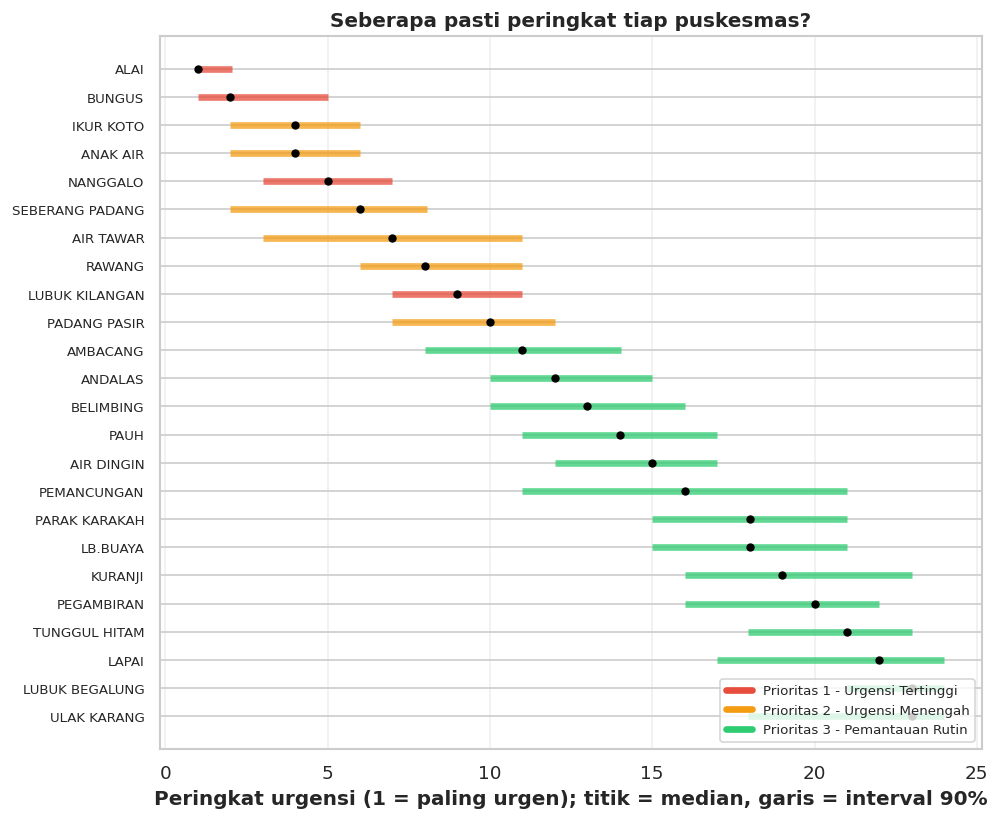

,Puskesmas,Kelompok,Skor_Urgensi,Peringkat_Median,Peringkat_P5,Peringkat_P95,Peluang_Top_k,Lebar_Interval,Kepastian_Peringkat
2,ALAI,Prioritas 1 - Urgensi Tertinggi,1.16,1.0,1.00,2.05,0.99,1.05,Atas (stabil)
7,BUNGUS,Prioritas 1 - Urgensi Tertinggi,0.92,2.0,1.00,5.00,0.93,4.00,Atas (stabil)
4,ANAK AIR,Prioritas 2 - Urgensi Menengah,0.60,4.0,2.00,6.00,0.54,4.00,Belum pasti
8,IKUR KOTO,Prioritas 2 - Urgensi Menengah,0.62,4.0,2.00,6.00,0.66,4.00,Belum pasti
14,NANGGALO,Prioritas 1 - Urgensi Tertinggi,0.62,5.0,3.00,7.00,0.44,4.00,Belum pasti
21,SEBERANG PADANG,Prioritas 2 - Urgensi Menengah,0.52,6.0,2.00,8.05,0.32,6.05,Belum pasti
1,AIR TAWAR,Prioritas 2 - Urgensi Menengah,0.45,7.0,3.00,11.00,0.12,8.00,Belum pasti
20,RAWANG,Prioritas 2 - Urgensi Menengah,0.24,8.0,6.00,11.00,0.00,5.00,Bukan atas (stabil)
13,LUBUK KILANGAN,Prioritas 1 - Urgensi Tertinggi,0.22,9.0,7.00,11.00,0.00,4.00,Bukan atas (stabil)
15,PADANG PASIR,Prioritas 2 - Urgensi Menengah,0.17,10.0,7.00,12.00,0.00,5.00,Bukan atas (stabil)


In [ ]:
B2 = 300
rng_r = np.random.default_rng(7)
peringkat = np.zeros((B2, len(daftar_pusk)))
for b in range(B2):
    boot = resample(arr_pusk, rng_r)      # resampling anak + variasi jumlah kasus (sama seperti 10c)
    Xb = fitur_dari(boot)
    skor_b = ((Xb - Xb.mean()) / Xb.std(ddof=0)).mean(axis=1)                         # skor urgensi per puskesmas
    peringkat[b] = skor_b.rank(ascending=False).to_numpy()

k_atas = int((df_puskesmas['Kelompok_Prioritas'] == NAMA_P[1]).sum())                 # ukuran kelompok Prioritas 1
tabel_rank = pd.DataFrame({
    'Puskesmas': daftar_pusk, 'Kelompok': df_puskesmas['Kelompok_Prioritas'].values, 'Skor_Urgensi': df_puskesmas['Skor_Urgensi'].values,
    'Peringkat_Median': np.median(peringkat, axis=0), 'Peringkat_P5': np.percentile(peringkat, 5, axis=0),
    'Peringkat_P95': np.percentile(peringkat, 95, axis=0), 'Peluang_Top_k': (peringkat <= k_atas).mean(axis=0)})
tabel_rank['Lebar_Interval'] = tabel_rank['Peringkat_P95'] - tabel_rank['Peringkat_P5']
tabel_rank['Kepastian_Peringkat'] = np.where(tabel_rank['Peluang_Top_k'] >= .9, 'Atas (stabil)',
                                    np.where(tabel_rank['Peluang_Top_k'] <= .1, 'Bukan atas (stabil)', 'Belum pasti'))
for kol in ['Peringkat_Median', 'Peringkat_P5', 'Peringkat_P95', 'Kepastian_Peringkat']:
    df_puskesmas[kol] = tabel_rank[kol].values

n_atas = int((tabel_rank['Kepastian_Peringkat'] == 'Atas (stabil)').sum())
n_bawah = int((tabel_rank['Kepastian_Peringkat'] == 'Bukan atas (stabil)').sum())
n_belum = int((tabel_rank['Kepastian_Peringkat'] == 'Belum pasti').sum())
lebar_med = float(tabel_rank['Lebar_Interval'].median())
print(f"=== INTERVAL PERINGKAT URGENSI (bootstrap {B2}x, interval 90%) ===")
print(f"- {n_atas} puskesmas stabil di kelompok atas (peluang >= 90% masuk {k_atas} teratas), {n_bawah} stabil bukan atas, {n_belum} belum pasti.")
print(f"- Lebar interval peringkat: median {lebar_med:.0f} dari {len(daftar_pusk)} peringkat.")
print("->", "Interval lebar: urutan rinci tidak boleh dibaca harfiah; sajikan sebagai rentang atau kelompok." if lebar_med >= 8
      else "Interval relatif sempit: urutan cukup stabil terhadap sampel anak.")
print("Catatan: bootstrap mengocok sampel anak dan jumlah kasus (Poisson). 'Atas' = masuk k teratas menurut skor urgensi gabungan 5 indikator (terpisah dari pembentukan kelompok). Bumil KEK dianggap tetap, dan anak yang sama di beberapa bulan dianggap independen.")

warna_k = {NAMA_P[1]: '#e74c3c', NAMA_P[2]: '#f39c12', NAMA_P[3]: '#2ecc71'}
u = tabel_rank.sort_values('Peringkat_Median', ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.5, 7), dpi=120)
for yi, r in u.iterrows():
    ax.hlines(yi, r['Peringkat_P5'], r['Peringkat_P95'], color=warna_k[r['Kelompok']], lw=4, alpha=.75)
    ax.plot(r['Peringkat_Median'], yi, 'o', color='black', ms=4)
ax.set_yticks(range(len(u))); ax.set_yticklabels(u['Puskesmas'], fontsize=8)
ax.set_xlabel('Peringkat urgensi (1 = paling urgen); titik = median, garis = interval 90%', fontweight='bold')
ax.set_title('Seberapa pasti peringkat tiap puskesmas?', fontweight='bold'); ax.grid(axis='x', alpha=.3)
ax.legend(handles=[plt.Line2D([0], [0], color=w, lw=4, label=n) for n, w in warna_k.items()], loc='lower right', fontsize=8)
plt.tight_layout(); plt.savefig('interval_peringkat_puskesmas_2026.png'); plt.show()
display(tabel_rank.sort_values('Peringkat_Median').round(2))


### 10h - Inti atau perbatasan? Seberapa yakin kelompok tiap puskesmas

Mengategorikan setiap puskesmas menjadi kelompok Inti (stabil dan konsisten) atau Perbatasan (memerlukan peninjauan lebih lanjut oleh Dinkes) berdasarkan hasil gabungan bootstrap dan nilai silhouette.

In [ ]:
keyak = kepastian[['Puskesmas', 'Kepastian_Keanggotaan_(%)', 'Status']].merge(
    df_puskesmas[['Puskesmas', 'Kelompok_Prioritas', 'Silhouette_sampel']], on='Puskesmas')
def kelas_keyakinan(r):
    if r['Status'] == 'Kokoh' and r['Silhouette_sampel'] >= 0: return 'Inti'
    if r['Status'] == 'Perbatasan' or r['Silhouette_sampel'] < 0: return 'Perbatasan'
    return 'Cukup'
keyak['Keyakinan_Kelompok'] = keyak.apply(kelas_keyakinan, axis=1)
df_puskesmas['Keyakinan_Kelompok'] = df_puskesmas['Puskesmas'].map(keyak.set_index('Puskesmas')['Keyakinan_Kelompok'])

n_total = len(df_puskesmas)
n_inti = int((keyak['Keyakinan_Kelompok'] == 'Inti').sum())
n_cukup = int((keyak['Keyakinan_Kelompok'] == 'Cukup').sum())
n_perb = int((keyak['Keyakinan_Kelompok'] == 'Perbatasan').sum())
print("=== KEYAKINAN KEANGGOTAAN KELOMPOK ===")
display(pd.crosstab(keyak['Kelompok_Prioritas'], keyak['Keyakinan_Kelompok']).reindex(columns=['Inti', 'Cukup', 'Perbatasan'], fill_value=0))
for k in ['Inti', 'Cukup', 'Perbatasan']:
    print(f"- {k} ({int((keyak['Keyakinan_Kelompok'] == k).sum())}): " + (", ".join(keyak.loc[keyak['Keyakinan_Kelompok'] == k, 'Puskesmas']) or "-"))
print(f"\n-> {n_inti} dari {n_total} puskesmas berstatus Inti ({n_inti / n_total * 100:.0f}%). Klaim kelompok yang kuat hanya berlaku untuk mereka.")

# Ekspor hasil uji ketahanan (lampiran laporan / slide)
with pd.ExcelWriter('Tabel_Uji_Ketahanan_2026.xlsx') as w:
    kepastian.to_excel(w, sheet_name='Bootstrap_Keanggotaan', index=False)
    tabel_sens.to_excel(w, sheet_name='Sensitivitas', index=False)
    tabel_rank.to_excel(w, sheet_name='Peringkat_Interval', index=False)
    keyak.to_excel(w, sheet_name='Keyakinan_Kelompok', index=False)
print("Tabel uji ketahanan berhasil diekspor: 'Tabel_Uji_Ketahanan_2026.xlsx'")


=== KEYAKINAN KEANGGOTAAN KELOMPOK ===


Keyakinan_Kelompok,Inti,Cukup,Perbatasan
Kelompok_Prioritas,,,
Prioritas 1 - Urgensi Tertinggi,3,0,1
Prioritas 2 - Urgensi Menengah,6,0,0
Prioritas 3 - Pemantauan Rutin,14,0,0


- Inti (23): AIR DINGIN, AIR TAWAR, ALAI, AMBACANG, ANAK AIR, ANDALAS, BELIMBING, BUNGUS, IKUR KOTO, KURANJI, LAPAI, LB.BUAYA, LUBUK BEGALUNG, NANGGALO, PADANG PASIR, PARAK KARAKAH, PAUH, PEGAMBIRAN, PEMANCUNGAN, RAWANG, SEBERANG PADANG, TUNGGUL HITAM, ULAK KARANG
- Cukup (0): -
- Perbatasan (1): LUBUK KILANGAN

-> 23 dari 24 puskesmas berstatus Inti (96%). Klaim kelompok yang kuat hanya berlaku untuk mereka.
Tabel uji ketahanan berhasil diekspor: 'Tabel_Uji_Ketahanan_2026.xlsx'


### 10i - Profil kelompok, ringkasan per kecamatan, dan peta

> Meringkas hasil menjadi tabel dan peta yang siap dipresentasikan, dan mengekspor tabel untuk aplikasi web.

=== PROFIL KELOMPOK (24 PUSKESMAS KOTA PADANG) ===


,Jml_Puskesmas,Prevalensi_Rerata,Sangat_Pendek_Rerata,Stunting_Wasting_Rerata,BB_Tidak_Naik_Rerata,Bumil_KEK_Rerata
Kelompok_Prioritas,,,,,,
Prioritas 1 - Urgensi Tertinggi,4,1.80,36.47,20.32,50.95,16.25
Prioritas 2 - Urgensi Menengah,6,6.86,20.43,17.58,46.05,12.97
Prioritas 3 - Pemantauan Rutin,14,2.07,20.44,17.42,33.56,9.70



Prioritas 1 - Urgensi Tertinggi (4 Puskesmas):
 -> ALAI, BUNGUS, LUBUK KILANGAN, NANGGALO

Prioritas 2 - Urgensi Menengah (6 Puskesmas):
 -> AIR TAWAR, ANAK AIR, IKUR KOTO, PADANG PASIR, RAWANG, SEBERANG PADANG

Prioritas 3 - Pemantauan Rutin (14 Puskesmas):
 -> AIR DINGIN, AMBACANG, ANDALAS, BELIMBING, KURANJI, LAPAI, LB.BUAYA, LUBUK BEGALUNG, PARAK KARAKAH, PAUH, PEGAMBIRAN, PEMANCUNGAN, TUNGGUL HITAM, ULAK KARANG

=== RINGKASAN PER KECAMATAN (P1/P2/P3 = jumlah puskesmas di tiap kelompok) ===


,Kecamatan,Jml_Puskesmas,Rerata_Kasus_per_Bulan,Sasaran_Balita,P1,P2,P3,Prevalensi_Kecamatan_(%)
0,NANGGALO,2,68.6,2726,1,0,1,2.52
1,PADANG UTARA,3,67.7,3692,1,1,1,1.83
2,LUBUK KILANGAN,1,74.7,4276,1,0,0,1.75
3,BUNGUS TELUK KABUNG,1,27.7,1872,1,0,0,1.48
4,PADANG SELATAN,3,144.0,3066,0,2,1,4.70
5,PADANG BARAT,1,63.7,1446,0,1,0,4.41
6,KOTO TANGAH,5,555.1,14775,0,2,3,3.76
7,PAUH,1,85.3,3136,0,0,1,2.72
8,PADANG TIMUR,2,112.0,4659,0,0,2,2.40
9,KURANJI,3,163.0,8124,0,0,3,2.01


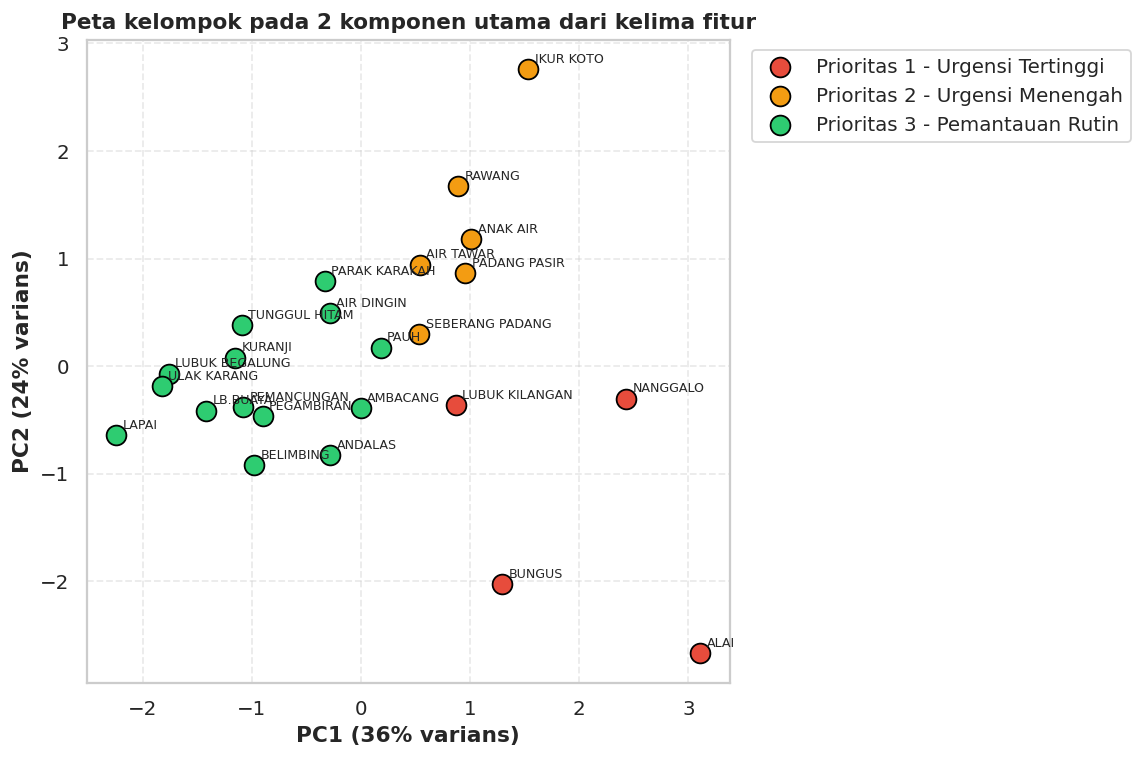

Tabel berhasil diekspor: 'Tabel_Final_Web_DSS_Puskesmas_2026.xlsx'


In [ ]:
# 1. Profil rata-rata tiap kelompok
profil_kelompok = df_puskesmas.groupby('Kelompok_Prioritas').agg(
    Jml_Puskesmas=('Puskesmas', 'count'),
    Prevalensi_Rerata=('Prevalensi_(%)', 'mean'),
    Sangat_Pendek_Rerata=('Sangat_pendek_(%)', 'mean'),
    Stunting_Wasting_Rerata=('Stunting_wasting_(%)', 'mean'),
    BB_Tidak_Naik_Rerata=('BB_tidak_naik_(%)', 'mean'),
    Bumil_KEK_Rerata=('Bumil_KEK_(%)', 'mean')
).round(2)
print("=== PROFIL KELOMPOK (24 PUSKESMAS KOTA PADANG) ===")
display(profil_kelompok)
for nama_klaster, grup in df_puskesmas.groupby('Kelompok_Prioritas'):
    print(f"\n{nama_klaster} ({len(grup)} Puskesmas):\n -> " + ", ".join(grup['Puskesmas'].tolist()))

# 2. Ringkasan per KECAMATAN (sesuai arahan dosen: fokus wilayah/kecamatan)
urut = {NAMA_P[i]: i for i in (1, 2, 3)}
df_puskesmas['_urut'] = df_puskesmas['Kelompok_Prioritas'].map(urut)
kec = df_puskesmas.groupby('Kecamatan').agg(
    Jml_Puskesmas=('Puskesmas', 'count'),
    Rerata_Kasus_per_Bulan=('Rerata_kasus_per_bulan', 'sum'),
    Sasaran_Balita=('Sasaran_balita_per_bulan', 'sum'),
    P1=('_urut', lambda s: (s == 1).sum()),
    P2=('_urut', lambda s: (s == 2).sum()),
    P3=('_urut', lambda s: (s == 3).sum()),
).reset_index()
kec['Prevalensi_Kecamatan_(%)'] = (kec['Rerata_Kasus_per_Bulan'] / kec['Sasaran_Balita'] * 100).round(2)
kec = kec.sort_values(['P1', 'Prevalensi_Kecamatan_(%)'], ascending=False).reset_index(drop=True)
print("\n=== RINGKASAN PER KECAMATAN (P1/P2/P3 = jumlah puskesmas di tiap kelompok) ===")
display(kec)
df_puskesmas = df_puskesmas.drop(columns='_urut')

# 3. Peta kelompok pada 2 komponen utama dari KELIMA fitur
palet_warna = {NAMA_P[1]: '#e74c3c', NAMA_P[2]: '#f39c12', NAMA_P[3]: '#2ecc71'}
pc = PCA(n_components=2).fit(X_scaled); P = pc.transform(X_scaled)
plt.figure(figsize=(9, 6), dpi=130)
for nama, warna in palet_warna.items():
    m = (df_puskesmas['Kelompok_Prioritas'] == nama).to_numpy()
    plt.scatter(P[m, 0], P[m, 1], s=120, c=warna, edgecolor='black', label=nama)
for i, p in enumerate(df_puskesmas['Puskesmas']): plt.text(P[i, 0] + 0.06, P[i, 1] + 0.06, p, fontsize=7)
plt.xlabel(f"PC1 ({pc.explained_variance_ratio_[0]*100:.0f}% varians)", fontweight='bold'); plt.ylabel(f"PC2 ({pc.explained_variance_ratio_[1]*100:.0f}% varians)", fontweight='bold')
plt.title('Peta kelompok pada 2 komponen utama dari kelima fitur', fontweight='bold'); plt.grid(True, ls='--', alpha=.4)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.tight_layout(); plt.savefig('peta_pca_puskesmas_padang_2026.png'); plt.show()

# 4. Usulan intervensi (HIPOTESIS awal, perlu divalidasi Dinkes/ahli gizi) & ekspor untuk web DSS
rekomendasi_dss = REKOMENDASI
df_puskesmas['Usulan_Kebijakan'] = df_puskesmas['Kelompok_Prioritas'].map(rekomendasi_dss)
with pd.ExcelWriter('Tabel_Final_Web_DSS_Puskesmas_2026.xlsx') as w:
    df_puskesmas.to_excel(w, sheet_name='Puskesmas', index=False)
    kec.to_excel(w, sheet_name='Kecamatan', index=False)
print("Tabel berhasil diekspor: 'Tabel_Final_Web_DSS_Puskesmas_2026.xlsx'")


### 10j - Kartu skor dan kesimpulan

> Merangkum semua uji dalam satu tabel. Penilaiannya memakai patokan praktis, bukan standar baku.

In [ ]:
ari_ward = adjusted_rand_score(df_puskesmas['Cluster_ID'], df_puskesmas['Ward_ID'])
n_kokoh = int((kepastian['Status'] == 'Kokoh').sum())

def nilai(v, tinggi, sedang, a='Kuat', b='Sedang', c='Lemah'):
    return a if v >= tinggi else (b if v >= sedang else c)

skor_berlapis = pd.DataFrame([
    ['1. Metrik internal',     'Seberapa tegas klaster terpisah?',                    f"Silhouette {sil_final:.3f} | DBI {dbi_final:.3f} | CHI {chi_final:.2f}", nilai(sil_final, .7, .5)],
    ['2. Lawan data acak',     'Apakah lebih baik dari kolom yang diacak?',            f"p = {p_perm:.3f}", 'Lolos' if p_perm < .05 else 'Tidak lolos'],
    ['3. Antar-algoritma',     'Apakah K-Means dan Ward sepakat? (ARI)',               f"{ari_ward:.2f}", nilai(ari_ward, .7, .4, 'Konsisten', 'Sebagian', 'Sensitif algoritma')],
    ['4. Antarbulan',          'Apakah pengelompokan tiap bulan konsisten? (ARI)',     f"Mar-Apr {ari_mar_apr:.2f} | Apr-Mei {ari_apr_mei:.2f}", nilai(min(ari_mar_apr, ari_apr_mei), .7, .5, 'Baik', 'Sedang', 'Lemah')],
    ['5. Bootstrap (300x)',    'Apakah keanggotaan tahan terhadap sampel anak?',       f"ARI rerata {np.mean(ari_list):.2f} (P10 {np.percentile(ari_list, 10):.2f}) | Kokoh {n_kokoh}/{len(kepastian)}", nilai(np.mean(ari_list), .7, .5)],
    ['6. Sensitivitas desain', 'Apakah Prioritas 1 tetap utuh saat K/fitur diubah?',   f"utuh pada {sum(utuh_list)}/{len(utuh_list)} varian", nilai(sum(utuh_list) / len(utuh_list), .8, .5)],
    ['7. Bukan satu dimensi',  'Berbeda dari klaster prevalensi saja?',                f"ARI vs prevalensi saja {ari_1d:.2f} | Spearman {rho_prev:.2f}", 'Multi-dimensi' if ari_1d < .7 else 'Mirip prevalensi'],
    ['8. Keyakinan per puskesmas', 'Berapa puskesmas yang keanggotaannya meyakinkan (Inti)?', f"Inti {n_inti}/{n_total} | Cukup {n_cukup} | Perbatasan {n_perb}", nilai(n_inti / n_total, .75, .5)],
], columns=['Lapisan', 'Pertanyaan', 'Hasil', 'Penilaian'])
print("=== KARTU SKOR UJI BERLAPIS (ambang penilaian adalah ambang praktis, bukan standar baku) ===")
display(skor_berlapis)
print(f"Informasi tambahan (tidak dinilai): kesepakatan split temporal Tahap 6 = ketat {hasil_split.iloc[1, 2]}% | relatif {hasil_split.iloc[2, 2]}%.")
print("Angka itu tidak dinilai karena kelompok acuannya memuat bulan uji, sehingga cenderung optimistis.")
print(f"Informasi tambahan (tidak dinilai): peringkat urgensi stabil pada {n_atas + n_bawah} dari {n_total} puskesmas (10g); diagnosis derau: {diag_derau}.")


=== KARTU SKOR UJI BERLAPIS (ambang penilaian adalah ambang praktis, bukan standar baku) ===


,Lapisan,Pertanyaan,Hasil,Penilaian
0,1. Metrik internal,Seberapa tegas klaster terpisah?,Silhouette 0.268 | DBI 1.234 | CHI 8.59,Lemah
1,2. Lawan data acak,Apakah lebih baik dari kolom yang diacak?,p = 0.146,Tidak lolos
2,3. Antar-algoritma,Apakah K-Means dan Ward sepakat? (ARI),0.24,Sensitif algoritma
3,4. Antarbulan,Apakah pengelompokan tiap bulan konsisten? (ARI),Mar-Apr 0.30 | Apr-Mei 0.39,Lemah
4,5. Bootstrap (300x),Apakah keanggotaan tahan terhadap sampel anak?,ARI rerata 0.68 (P10 0.34) | Kokoh 23/24,Sedang
5,6. Sensitivitas desain,Apakah Prioritas 1 tetap utuh saat K/fitur diu...,utuh pada 3/6 varian,Sedang
6,7. Bukan satu dimensi,Berbeda dari klaster prevalensi saja?,ARI vs prevalensi saja 0.41 | Spearman 0.41,Multi-dimensi
7,8. Keyakinan per puskesmas,Berapa puskesmas yang keanggotaannya meyakinka...,Inti 23/24 | Cukup 0 | Perbatasan 1,Kuat


Informasi tambahan (tidak dinilai): kesepakatan split temporal Tahap 6 = ketat 58.3% | relatif 91.7%.
Angka itu tidak dinilai karena kelompok acuannya memuat bulan uji, sehingga cenderung optimistis.
Informasi tambahan (tidak dinilai): peringkat urgensi stabil pada 19 dari 24 puskesmas (10g); diagnosis derau: indikator cukup andal (reliabilitas rata-rata 0.57) dan koreksi tidak banyak mengubah kestabilan antarbulan (0.34 -> 0.27); jadi lemahnya kestabilan kemungkinan karena pola yang memang berubah antarbulan, bukan karena angka kecil.


In [ ]:
print("KESIMPULAN EVALUASI (ditulis otomatis dari kartu skor di atas)\n")
BAIK = {'Kuat', 'Lolos', 'Konsisten', 'Baik', 'Multi-dimensi'}
SEDANG = {'Sedang', 'Sebagian'}
kuat = skor_berlapis[skor_berlapis['Penilaian'].isin(BAIK)]['Lapisan'].tolist()
sedang = skor_berlapis[skor_berlapis['Penilaian'].isin(SEDANG)]['Lapisan'].tolist()
lemah = skor_berlapis[~skor_berlapis['Penilaian'].isin(BAIK | SEDANG)]['Lapisan'].tolist()
print(f"- Uji yang hasilnya baik ({len(kuat)} dari {len(skor_berlapis)}): " + (", ".join(kuat) or "-"))
print(f"- Uji yang hasilnya sedang ({len(sedang)}): " + (", ".join(sedang) or "-"))
print(f"- Uji yang hasilnya lemah / perlu perhatian ({len(lemah)}): " + (", ".join(lemah) or "-"))
perbatasan = df_puskesmas.loc[df_puskesmas['Silhouette_sampel'] < 0, 'Puskesmas'].tolist()
print("- Puskesmas di perbatasan menurut silhouette (negatif): " + (", ".join(perbatasan) or "tidak ada"))
rapuh = kepastian.loc[kepastian['Status'] == 'Perbatasan', 'Puskesmas'].tolist()
print("- Puskesmas yang keanggotaannya kurang kokoh di bootstrap (di bawah 70%): " + (", ".join(rapuh) or "tidak ada"))

print("\nCARA MENYEBUT HASIL INI")
if len(lemah) >= 2:
    print(f"- Ada {len(lemah)} dari {len(skor_berlapis)} uji yang lemah, jadi bukti adanya kelompok alami yang tegas masih lemah. Sebut hasil ini sebagai")
    print("  'pemeringkatan profil prioritas berdasarkan 5 indikator' yang perlu divalidasi Dinkes, BUKAN 'ditemukan 3 kelompok alami' dan bukan klasifikasi pasti.")
else:
    print("- Sebagian besar uji mendukung adanya struktur kelompok" + (f", kecuali: {', '.join(lemah)}" if lemah else "") + ".")
    print("  Tetap sebut hasil ini alat bantu prioritas yang perlu divalidasi Dinkes, bukan klasifikasi pasti.")
cz_k = centroid_z(df_puskesmas, df_puskesmas['Cluster_ID'])
c_prev = int(cz_k['Prevalensi_(%)'].idxmax())
if peta_prioritas[c_prev] != NAMA_P[1]:
    print(f"- PERHATIAN: kelompok dengan prevalensi tertinggi adalah '{peta_prioritas[c_prev]}', bukan Prioritas 1. Prioritas 1 ditentukan rata-rata 5 indikator")
    print("  berbobot sama. Jelaskan ini saat presentasi, dan cek apakah prevalensi rendah di kelompok tersebut karena pelaporan kasus belum lengkap.")
print("\nCARA MENYAJIKAN HASIL")
print(f"- Keanggotaan kelompok: {n_inti} puskesmas berstatus Inti (boleh diklaim kuat), {n_cukup} Cukup, {n_perb} Perbatasan (sebut 'belum pasti').")
print(f"- Peringkat urgensi: {n_atas + n_bawah} dari {n_total} puskesmas peringkatnya stabil; {n_belum} belum pasti (lebar interval median {lebar_med:.0f} peringkat).")
print(f"- Angka kasus kecil: {diag_derau}.")
print("\nBATASAN")
print("- Data hanya 3 bulan, jadi kesimpulan berupa potret, bukan tren. Validasi Dinkes/ahli gizi dan data yang lebih panjang diperlukan sebelum dipakai untuk keputusan anggaran.")
print("- Faktor kemiskinan dan sanitasi belum dimodelkan karena data resmi per puskesmas belum tersedia.")


KESIMPULAN EVALUASI (ditulis otomatis dari kartu skor di atas)

- Uji yang hasilnya baik (2 dari 8): 7. Bukan satu dimensi, 8. Keyakinan per puskesmas
- Uji yang hasilnya sedang (2): 5. Bootstrap (300x), 6. Sensitivitas desain
- Uji yang hasilnya lemah / perlu perhatian (4): 1. Metrik internal, 2. Lawan data acak, 3. Antar-algoritma, 4. Antarbulan
- Puskesmas di perbatasan menurut silhouette (negatif): LUBUK KILANGAN
- Puskesmas yang keanggotaannya kurang kokoh di bootstrap (di bawah 70%): tidak ada

CARA MENYEBUT HASIL INI
- Ada 4 dari 8 uji yang lemah, jadi bukti adanya kelompok alami yang tegas masih lemah. Sebut hasil ini sebagai
  'pemeringkatan profil prioritas berdasarkan 5 indikator' yang perlu divalidasi Dinkes, BUKAN 'ditemukan 3 kelompok alami' dan bukan klasifikasi pasti.
- PERHATIAN: kelompok dengan prevalensi tertinggi adalah 'Prioritas 2 - Urgensi Menengah', bukan Prioritas 1. Prioritas 1 ditentukan rata-rata 5 indikator
  berbobot sama. Jelaskan ini saat presentasi, dan

## Tahap 11 - Finalisasi Model (Menyimpan Model)

Menyimpan model klasterisasi final, pemetaan prioritas, serta metadata batasan ke dalam satu berkas (model_klaster_puskesmas_2026.pkl), dilanjutkan dengan pengujian muat ulang untuk memastikan berkas berfungsi konsisten sebelum digunakan pada aplikasi web.

In [ ]:
rekomendasi_kelompok = REKOMENDASI
pipeline_final = Pipeline([('scaler', StandardScaler()), ('kmeans', KMeans(n_clusters=K, random_state=SEED, n_init=N_INIT))]).fit(X)   # fitted; identik dengan model di Tahap 8
paket = {
    'pipeline': pipeline_final, 'mapping': peta_prioritas, 'features': fitur_klaster,     # kunci yang dipakai backend DSS
    'rekomendasi': rekomendasi_kelompok,
    'referensi_fitur': {'rerata': df_puskesmas[fitur_klaster].mean().to_dict(), 'simpangan_baku': df_puskesmas[fitur_klaster].std().to_dict()},
    'versi': '1.0', 'tanggal_latih': datetime.date.today().isoformat(),
}
joblib.dump(paket, 'model_klaster_puskesmas_2026.pkl')

batasan = ['Data hanya 3 bulan (potret, bukan tren)', 'BNBA hanya memuat balita stunting; prevalensi = kasus tercatat / sasaran',
           'Tidak memuat data kemiskinan/sanitasi (tidak tersedia data resmi per puskesmas)']
if sil_final < 0.5: batasan.append(f'Pemisahan antar kelompok tidak tegas (silhouette {sil_final:.2f})')
if (geser['Selisih (x simpangan baku antar-puskesmas)'].abs() >= 0.5).any(): batasan.append('Level indikator bergeser antarbulan; gunakan standardisasi relatif untuk data baru')
if (df_puskesmas['Keyakinan_Kelompok'] == 'Perbatasan').any(): batasan.append('Sebagian puskesmas berstatus Perbatasan; keanggotaan kelompoknya belum pasti (lihat Keyakinan_Kelompok)')
metadata = {
    'nama_model': 'Klasterisasi Puskesmas Kota Padang berdasarkan stunting (K-Means K=3)',
    'periode_data': 'Maret-Mei 2026 (3 bulan)', 'jumlah_puskesmas': int(len(df_puskesmas)),
    'jumlah_baris_anak_valid': int(len(df_bersih)), 'fitur': fitur_klaster,
    'parameter': {'algoritma': 'KMeans', 'n_clusters': 3, 'n_init': 200, 'random_state': 42, 'scaler': 'StandardScaler'},
    'metrik': {'silhouette': round(float(sil_final), 3), 'davies_bouldin': round(float(dbi_final), 3), 'calinski_harabasz': round(float(chi_final), 2)},
    'kelompok': {peta_prioritas[i]: int((df_puskesmas['Cluster_ID'] == i).sum()) for i in range(3)},
    'aturan_penamaan': 'Skor urgensi = rata-rata z-score pusat klaster pada 5 fitur (bobot sama); tertinggi = Prioritas 1',
    'batasan': batasan,
}
with open('metadata_model_2026.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

# Uji muat ulang: hasilnya harus identik dengan model di memori
muat = joblib.load('model_klaster_puskesmas_2026.pkl')
pred_muat = muat['pipeline'].predict(df_puskesmas[muat['features']])
assert (pred_muat == df_puskesmas['Cluster_ID'].to_numpy()).all(), "Model hasil muat ulang berbeda dari model di memori!"
print("Model tersimpan dan lolos uji muat ulang (prediksi identik untuk 24 puskesmas).")
print("Berkas keluaran: model_klaster_puskesmas_2026.pkl | metadata_model_2026.json | Tabel_Final_Web_DSS_Puskesmas_2026.xlsx | Tabel_Uji_Ketahanan_2026.xlsx | peta_pca_puskesmas_padang_2026.png | interval_peringkat_puskesmas_2026.png")
print(json.dumps(metadata['metrik'], indent=2))


Model tersimpan dan lolos uji muat ulang (prediksi identik untuk 24 puskesmas).
Berkas keluaran: model_klaster_puskesmas_2026.pkl | metadata_model_2026.json | Tabel_Final_Web_DSS_Puskesmas_2026.xlsx | Tabel_Uji_Ketahanan_2026.xlsx | peta_pca_puskesmas_padang_2026.png | interval_peringkat_puskesmas_2026.png
{
  "silhouette": 0.268,
  "davies_bouldin": 1.234,
  "calinski_harabasz": 8.59
}


## Tahap 12 - Deployment & Monitoring (Memakai dan Memantau)

Menggunakan model final untuk memproses data bulan baru serta memantau potensi pergeseran pola kelompok. Penerapan operasional dilakukan melalui berkas aplikasi terpisah (app_ass.py) agar dapat diakses langsung oleh Dinas Kesehatan dan pihak puskesmas.

In [ ]:
def prediksi_kelompok(df_fitur, mode='relatif', paket_model=muat):
    """df_fitur: tabel dengan 5 kolom fitur (urutan sama dengan paket_model['features']). Mengembalikan nama kelompok + usulan."""
    fts = paket_model['features']; pipe = paket_model['pipeline']
    X_in = df_fitur[fts].astype(float)
    if mode == 'relatif':
        if len(X_in) < 10:
            raise ValueError("Mode 'relatif' butuh minimal 10 puskesmas dalam satu periode; gunakan mode='ketat' untuk data sedikit.")
        Z = ((X_in - X_in.mean()) / X_in.std(ddof=0)).to_numpy()   # standardisasi terhadap periode itu sendiri
    else:
        Z = pipe.named_steps['scaler'].transform(X_in)          # statistik data latih
    kode = pipe.named_steps['kmeans'].predict(Z)
    nama = pd.Series(kode, index=df_fitur.index).map(paket_model['mapping'])
    return pd.DataFrame({'Kelompok_Prioritas': nama, 'Usulan': nama.map(paket_model['rekomendasi'])})

# Demo 1: seluruh puskesmas bulan Mei (data bulanan) - mode relatif
mei = agg_bulanan[agg_bulanan['Bulan'] == '2026-05'].set_index('Puskesmas')
hasil_mei = prediksi_kelompok(mei, mode='relatif')
print("Distribusi kelompok (Mei, mode relatif):", hasil_mei['Kelompok_Prioritas'].value_counts().to_dict())

# Demo 2: satu puskesmas hipotetis (mode ketat) - input manual bidan
contoh = pd.DataFrame([{'Prevalensi_(%)': 5.2, 'Sangat_pendek_(%)': 22.0, 'Stunting_wasting_(%)': 18.0, 'BB_tidak_naik_(%)': 45.0, 'Bumil_KEK_(%)': 12.0}], index=['PUSKESMAS CONTOH'])
display(prediksi_kelompok(contoh, mode='ketat'))


Distribusi kelompok (Mei, mode relatif): {'Prioritas 3 - Pemantauan Rutin': 15, 'Prioritas 2 - Urgensi Menengah': 7, 'Prioritas 1 - Urgensi Tertinggi': 2}


,Kelompok_Prioritas,Usulan
PUSKESMAS CONTOH,Prioritas 2 - Urgensi Menengah,Usulan: penguatan pada indikator yang menonjol...


**12b. Pemantauan.**

Setiap kali data BNBA bulan baru masuk, jalankan pemeriksaan ini sebelum hasilnya dipakai.

| Yang dipantau | Cara | Ambang | Tindakan |
|---|---|---|---|
| Kualitas data masuk | Persentase baris yang dibuang saat pembersihan | Naik tajam dibanding bulan lalu | Cek format file BNBA (kolom bergeser, tanggal salah) |
| Pergeseran level indikator | `cek_pemantauan` (selisih rata-rata dalam SD) | >= 0,5 waspada, >= 1,0 kritis | Pakai mode `relatif`; telusuri penyebabnya |
| Perpindahan kelompok | % puskesmas pindah kelompok vs acuan | Banyak berpindah dalam sebulan | Tinjau bersama Dinkes sebelum mengubah prioritas |
| Sasaran dan Bumil KEK | Perbarui `sasaran_dict` dan `bumil_kek_dict` tiap ada rekap baru | Saat rekap Dinkes terbit | Latih ulang model |
| Latih ulang | Terjadwal | Tiap tambah 3 bulan data, atau setelah 12 bulan | Ulangi Tahap 5-11 dan arsipkan versi lama |
| Validasi pakar | Tinjauan Dinkes/ahli gizi atas nama kelompok dan usulan | Sebelum dipakai untuk anggaran | Revisi usulan |

**Pengembangan berikutnya:** tambah data hingga minimal 12 bulan (tren dan musiman), tambah data balita non-stunting agar prevalensi sebenarnya bisa dihitung, dan uji pada level kecamatan/desa.

In [ ]:
def cek_pemantauan(agg_baru, referensi=df_puskesmas, paket_model=muat, ambang_waspada=0.5, ambang_kritis=1.0):
    """agg_baru: fitur per puskesmas untuk SATU bulan baru (hasil hitung_fitur(..., 1))."""
    fts = paket_model['features']
    baru = agg_baru.set_index('Puskesmas')[fts]
    ref = referensi.set_index('Puskesmas')[fts]
    # 1) Pergeseran level fitur (dalam satuan simpangan baku antar-puskesmas data acuan)
    geser = ((baru.mean() - ref.mean()) / ref.std()).round(2)
    status = geser.abs().apply(lambda v: 'KRITIS' if v >= ambang_kritis else ('waspada' if v >= ambang_waspada else 'normal'))
    drift = pd.DataFrame({'Pergeseran (x SD)': geser, 'Status': status})
    # 2) Perubahan kelompok vs acuan (mode relatif)
    pred = prediksi_kelompok(agg_baru.set_index('Puskesmas'), mode='relatif')['Kelompok_Prioritas']
    acuan_k = referensi.set_index('Puskesmas')['Kelompok_Prioritas'].reindex(pred.index)
    berubah = pred[pred != acuan_k]
    pct_sama = (pred == acuan_k).mean() * 100
    return drift, pct_sama, berubah

for bln in BULAN:
    drift, pct_sama, berubah = cek_pemantauan(agg_bulanan[agg_bulanan['Bulan'] == bln])
    print(f"\n=== {bln}: {pct_sama:.0f}% puskesmas sekelompok dengan acuan 3 bulan | berubah: {len(berubah)} ===")
    if len(berubah): print("Berpindah kelompok:", ", ".join(f"{p} ({k.split(' - ')[0]})" for p, k in berubah.items()))
    display(drift[drift['Status'] != 'normal'] if (drift['Status'] != 'normal').any() else "Semua fitur dalam batas normal")



=== 2026-03: 96% puskesmas sekelompok dengan acuan 3 bulan | berubah: 1 ===
Berpindah kelompok: AMBACANG (Prioritas 1)


,Pergeseran (x SD),Status
BB_tidak_naik_(%),-0.96,waspada



=== 2026-04: 96% puskesmas sekelompok dengan acuan 3 bulan | berubah: 1 ===
Berpindah kelompok: PAUH (Prioritas 2)


'Semua fitur dalam batas normal'


=== 2026-05: 92% puskesmas sekelompok dengan acuan 3 bulan | berubah: 2 ===
Berpindah kelompok: BUNGUS (Prioritas 3), LUBUK KILANGAN (Prioritas 2)


,Pergeseran (x SD),Status
BB_tidak_naik_(%),0.7,waspada


**12c. Satu fungsi untuk bulan baru.**

`proses_bulan_baru()` menjalankan seluruh alur sekaligus: muat file BNBA, bersihkan, hitung fitur, prediksi kelompok, lalu cek pemantauan. Di bawah dicoba memakai file Mei sebagai contoh (Mei ikut dilatih, jadi ini hanya peragaan cara pakai).

In [ ]:
def proses_bulan_baru(path_bnba, bulan, mode='relatif', paket_model=None):
    """Satu fungsi untuk bulan baru: muat BNBA -> bersihkan -> hitung fitur -> prediksi kelompok -> cek pemantauan.
    path_bnba: file BNBA satu bulan; bulan: teks 'YYYY-MM'."""
    paket_model = paket_model or muat
    mentah = muat_bulan(path_bnba, bulan)
    bersih = bersihkan_data(mentah, verbose=False)
    asing = sorted(set(bersih['Pukesmas']) - set(sasaran_dict))
    if asing:
        print("Puskesmas tidak ada di kamus sasaran (dilewati, perbarui sasaran_dict):", ", ".join(asing))
        bersih = bersih[~bersih['Pukesmas'].isin(asing)]
    persen_dibuang = (1 - len(bersih) / max(len(mentah), 1)) * 100
    fitur_baru = hitung_fitur(bersih.groupby(['Kec', 'Pukesmas']), 1).sort_values('Puskesmas').reset_index(drop=True)
    hasil = prediksi_kelompok(fitur_baru.set_index('Puskesmas'), mode=mode, paket_model=paket_model)
    drift, pct_sama, berubah = cek_pemantauan(fitur_baru, paket_model=paket_model)
    print(f"Bulan {bulan}: {len(bersih)} baris dipakai ({persen_dibuang:.1f}% dibuang saat pembersihan) | {pct_sama:.0f}% puskesmas sekelompok dengan acuan 3 bulan")
    if len(berubah):
        print("Berpindah kelompok:", ", ".join(f"{p} ({k.split(' - ')[0]})" for p, k in berubah.items()))
    return {'hasil': hasil, 'fitur': fitur_baru, 'pergeseran': drift, 'berpindah': berubah, 'persen_dibuang': persen_dibuang}

# Contoh pemakaian dengan file Mei (Mei ikut dilatih, jadi ini hanya peragaan cara pakai)
contoh = proses_bulan_baru(file_bulan['2026-05'], '2026-05')
display(contoh['hasil']['Kelompok_Prioritas'].value_counts().to_frame('Jumlah puskesmas'))
display(contoh['pergeseran'])


[2026-05] baris mentah 4604 | blok bergeser dibuang 1472 | beda bulan dibuang 1487 | dipakai 1645
Bulan 2026-05: 1612 baris dipakai (2.0% dibuang saat pembersihan) | 92% puskesmas sekelompok dengan acuan 3 bulan
Berpindah kelompok: BUNGUS (Prioritas 3), LUBUK KILANGAN (Prioritas 2)


,Jumlah puskesmas
Kelompok_Prioritas,
Prioritas 3 - Pemantauan Rutin,15
Prioritas 2 - Urgensi Menengah,7
Prioritas 1 - Urgensi Tertinggi,2


,Pergeseran (x SD),Status
Prevalensi_(%),0.06,normal
Sangat_pendek_(%),-0.25,normal
Stunting_wasting_(%),-0.17,normal
BB_tidak_naik_(%),0.70,waspada
Bumil_KEK_(%),0.00,normal


##Pengarsipan Luaran Model

Mengemas seluruh berkas hasil pemodelan dan evaluasi (model .pkl, metadata JSON, tabel Excel, serta visualisasi) ke dalam satu arsip ZIP (hasil_klaster_stunting_2026.zip) untuk dokumentasi.

In [ ]:
# ==== SEL TERAKHIR: KEMAS SEMUA HASIL JADI SATU ZIP ====
daftar_hasil = ['model_klaster_puskesmas_2026.pkl', 'metadata_model_2026.json', 'Tabel_Final_Web_DSS_Puskesmas_2026.xlsx',
                'Tabel_Uji_Ketahanan_2026.xlsx', 'peta_pca_puskesmas_padang_2026.png', 'interval_peringkat_puskesmas_2026.png']
ada = [f for f in daftar_hasil if os.path.exists(f)]
with zipfile.ZipFile('hasil_klaster_stunting_2026.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for f in ada:
        z.write(f)
print("Isi zip:", ", ".join(ada))
try:
    from google.colab import files
    files.download('hasil_klaster_stunting_2026.zip')      # otomatis terunduh di Colab
except ImportError:
    print("Bukan Google Colab: ambil 'hasil_klaster_stunting_2026.zip' dari folder kerja.")


Isi zip: model_klaster_puskesmas_2026.pkl, metadata_model_2026.json, Tabel_Final_Web_DSS_Puskesmas_2026.xlsx, Tabel_Uji_Ketahanan_2026.xlsx, peta_pca_puskesmas_padang_2026.png, interval_peringkat_puskesmas_2026.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>